In [1]:
# Data Science
from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import PLSRegression, PLSCanonical
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import sklearn
import numpy as np
import pandas as pd
from scipy.stats import pearsonr
import scipy

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from PIL import Image
import matplotlib.cm as cm
import matplotlib as mpl
import networkx as nx

# Single-cell RNA sequencing libraries
import anndata
import scanpy as sc
import gseapy as gp
from gseapy import enrichment_map

# General tools
import sys
import os
import logging
from roman import toRoman, fromRoman
from pathlib import Path
from tqdm import tqdm
import joblib
from joblib import Parallel, delayed
import time
import re
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
# --- Helper function ---
def overlap(lst1, lst2):
    lst3 = [value for value in lst1 if value in lst2]
    return lst3

In [3]:
# Saved in python.package.version.txt
!conda list

# packages in environment at /host/aristotle/pool8_z0/miniconda3/envs/MERFISH:
#
# Name                    Version                   Build  Channel
_libgcc_mutex             0.1                 conda_forge    conda-forge
_openmp_mutex             4.5                       2_gnu    conda-forge
abc-atlas-access          0.5.0                    pypi_0    pypi
anndata                   0.11.4                   pypi_0    pypi
annotated-types           0.7.0                    pypi_0    pypi
archspec                  0.2.5              pyhd8ed1ab_0    conda-forge
array-api-compat          1.11.2                   pypi_0    pypi
asttokens                 3.0.0              pyhd8ed1ab_1    conda-forge
boltons                   24.0.0             pyhd8ed1ab_1    conda-forge
boto3                     1.37.24                  pypi_0    pypi
botocore                  1.37.24                  pypi_0    pypi
brotli-python             1.1.0           py313h46c70d0_2    conda-forge
bzip2             

# Psychedelics data

## Loading data

In [4]:
# --- Load and inspect data ---
adata_path = '../../../../psy_combined_clean_label.h5ad'
if not os.path.exists(adata_path):
    raise FileNotFoundError(f"{adata_path} not found.")

gene_exp = sc.read_h5ad(adata_path)
print(f"Expression matrix shape: {gene_exp.X.shape}")  # (n_cells, n_genes)

# --- Extract metadata ---
genes = gene_exp.var_names
cells = gene_exp.obs_names

gene_exp_df = pd.DataFrame(gene_exp.X.toarray(),
                           index = gene_exp.obs.index,
                           columns=gene_exp.var.index)

gene_exp_df = gene_exp_df.merge(gene_exp.obs,
                                left_index=True,
                                right_index=True)

genes_list = list(gene_exp.var.index) 
cell_types = np.unique(gene_exp_df.subtype)
print(f"Number of unique cell types: {len(cell_types)}")

# --- Save list of genes for later use ---
np.save('list_of_mouse_genes.npy', genes.to_numpy())
print(f"Saved {len(genes)} gene names to 'list_of_mouse_genes.npy'.")


# --- Identify serotonin-related genes (Htr*) in this dataset ---
bagot_sero = [gene for gene in genes if gene.startswith('Htr')]
print(f"Identified {len(bagot_sero)} serotonin receptor genes (Htr*) in dataset: {bagot_sero}")


# --- Load MERFISH gene list and find overlap ---
merfish_path = 'MERFISH_genes_list.npy'
if not os.path.exists(merfish_path):
    raise FileNotFoundError(f"{merfish_path} not found.")

MERFISH_genes = np.load(merfish_path, allow_pickle=True)
MERFISH_genes = list(map(str, MERFISH_genes))  # ensure string type
print(f"Loaded {len(MERFISH_genes)} MERFISH genes.")

# Overlapping genes between datasets
overlap_genes = overlap(genes, MERFISH_genes)
print(f"Overlap between datasets: {len(overlap_genes)} genes.")


# --- Identify serotonin-related genes (Htr*) in MERFISH ---
MERFISH_sero = [gene for gene in MERFISH_genes if gene.startswith('Htr')]
print(f"Identified {len(MERFISH_sero)} serotonin receptor genes (Htr*) in MERFISH: {MERFISH_sero}")

# Overlap between serotonin genes in both datasets
shared_sero = overlap(MERFISH_sero, bagot_sero)
print(f"Serotonin receptor genes shared between datasets: {shared_sero}")


# --- Load known serotonin genes (from JSON reference) ---
json_path = 'serotonin.json'
if not os.path.exists(json_path):
    raise FileNotFoundError(f"{json_path} not found.")

sero_genes = pd.read_json(json_path)
sero_symbols = sero_genes['approvedSymbol'].str.upper().tolist()
print(f"Loaded {len(sero_symbols)} curated serotonin-related gene symbols.")

# Compare with overlapping genes
genes_upper = [gene.upper() for gene in overlap_genes]
sero_genes_over = overlap(sero_symbols, genes_upper)
print(f"Number of serotonin-related genes overlapping across datasets: {len(sero_genes_over)}")
print(f"Overlapping serotonin genes: {sero_genes_over}")


# --- Known serotonin receptor genes in mouse (for reference) ---
sero_mouse = sorted([
    'Htr5b', 'Htr1d', 'Htr3a', 'Htr1b', 'Htr1a',
    'Htr2a', 'Htr1f', 'Htr4', 'Htr7', 'Htr2c'
])
print(f"Reference serotonin receptor genes in mouse: {sero_mouse}")


Expression matrix shape: (39435, 24600)
Number of unique cell types: 11
Saved 24600 gene names to 'list_of_mouse_genes.npy'.
Identified 17 serotonin receptor genes (Htr*) in dataset: ['Htr2b', 'Htr5b', 'Htr1d', 'Htr6', 'Htr5a', 'Htra3', 'Htra2', 'Htra1', 'Htra4', 'Htr3a', 'Htr1b', 'Htr1a', 'Htr2a', 'Htr1f', 'Htr4', 'Htr7', 'Htr2c']
Loaded 8460 MERFISH genes.
Overlap between datasets: 8264 genes.
Identified 13 serotonin receptor genes (Htr*) in MERFISH: ['Htr2a', 'Htr2c', 'Htr1f', 'Htr1b', 'Htra1', 'Htr1a', 'Htr4', 'Htr7', 'Htr1d', 'Htr3a', 'Htr5b', 'Htr3b', 'Htra3']
Serotonin receptor genes shared between datasets: ['Htr2a', 'Htr2c', 'Htr1f', 'Htr1b', 'Htra1', 'Htr1a', 'Htr4', 'Htr7', 'Htr1d', 'Htr3a', 'Htr5b', 'Htra3']
Loaded 18 curated serotonin-related gene symbols.
Number of serotonin-related genes overlapping across datasets: 9
Overlapping serotonin genes: ['HTR1A', 'HTR1B', 'HTR1D', 'HTR1F', 'HTR2A', 'HTR2C', 'HTR4', 'HTR7', 'HTR3A']
Reference serotonin receptor genes in mouse: [

## Running PLS

In [5]:
date = 'October_2025'

for cell_type in cell_types:
    
    print(cell_type)

    # Cell type and genes subsetting
    subset_df = gene_exp_df.loc[gene_exp_df.subtype == cell_type]
    genes_df = subset_df[overlap_genes]
    print(genes_df.shape)

    # 1 for 'PSY', -1 for SAL
    condition = pd.get_dummies(subset_df.condition, dtype=int)['PSY'].replace(0, -1).to_numpy()

    # Standardize the log-normalized matrix (towards zero mean, unit variance)
    genes_zscored = StandardScaler().fit_transform(genes_df)

    # ---------------------------
    # Dimensionality reduction with PCA
    # ---------------------------
    pca = PCA(n_components=100, random_state=42)  # Reduce to 100 principal components
    data_compressed = pca.fit_transform(genes_zscored)
    print(data_compressed.shape)
    # Save PCA object 
    joblib.dump(pca, f'{date}/pls_pca/pca_{cell_type}.gz')

    # ---------------------------
    # Partial Least Squares Regression (PLS)
    # ---------------------------
    # Important: scale=False to keep PCA scale
    pls = PLSRegression(n_components=20, scale=False)
    print(f'     Computing PLS!')
    pls.fit(data_compressed, condition)
    # Save the trained PLS model
    joblib.dump(pls, f'{date}/pls_pca/pls_{cell_type}.gz')
    # Compute Pearson correlation between each pair of PLS x- and y-scores
    # (captures explained variance of each component)
    actual_Rs = np.array([pearsonr(X_coef, Y_coef)[0] 
                          for X_coef, Y_coef in zip(pls.x_scores_.T, pls.y_scores_.T)])

    # ---------------------------
    # Extract and transform loadings
    # ---------------------------
    # Transform x-loadings (PCA scale) back to original gene space
    x_loadings = pca.inverse_transform(pls.x_loadings_.T)
    y_loadings = pls.y_loadings_

    # Orient each PLS component based on its correlation with the condition
    # Ensures that higher gene module expression aligns with psilocybin treatment
    sign = []
    for comp in range(0, 20): 
        rho = float(np.sign(pearsonr(pls.x_scores_[:, comp], condition)[0]))
        sign.append(rho)

    # Flip x-loadings according to the component sign to ensure consistency
    x_flipped = x_loadings.T * np.array(sign)
    # Save the flipped x-loadings and y-loadings for this cell type
    np.save(f'{date}/pls_pca/flipped/x_loadings_{cell_type}.npy', x_flipped.T)
    np.save(f'{date}/pls_pca/flipped/y_loadings_{cell_type}.npy', y_loadings)


Astro
(13079, 8264)
(13079, 100)
     Computing PLS!
Endo
(4559, 8264)
(4559, 100)
     Computing PLS!
GABA
(944, 8264)
(944, 100)
     Computing PLS!
L2-5_IT
(2495, 8264)
(2495, 100)
     Computing PLS!
L5-6_NP
(429, 8264)
(429, 100)
     Computing PLS!
L5_PT
(399, 8264)
(399, 100)
     Computing PLS!
L6_CT
(2139, 8264)
(2139, 100)
     Computing PLS!
Micro
(2550, 8264)
(2550, 100)
     Computing PLS!
NFO
(1718, 8264)
(1718, 100)
     Computing PLS!
OPC
(4809, 8264)
(4809, 100)
     Computing PLS!
Oligo
(6314, 8264)
(6314, 100)
     Computing PLS!


## Plotting scores

In [6]:
# Order the cell types to be consistent with other figures
cell_types_ordered = ['L2-5_IT', 'L5_PT', 'L5-6_NP', 'L6_CT', 'GABA', 'Astro', 'Endo', 'Micro', 'Oligo', 'OPC']

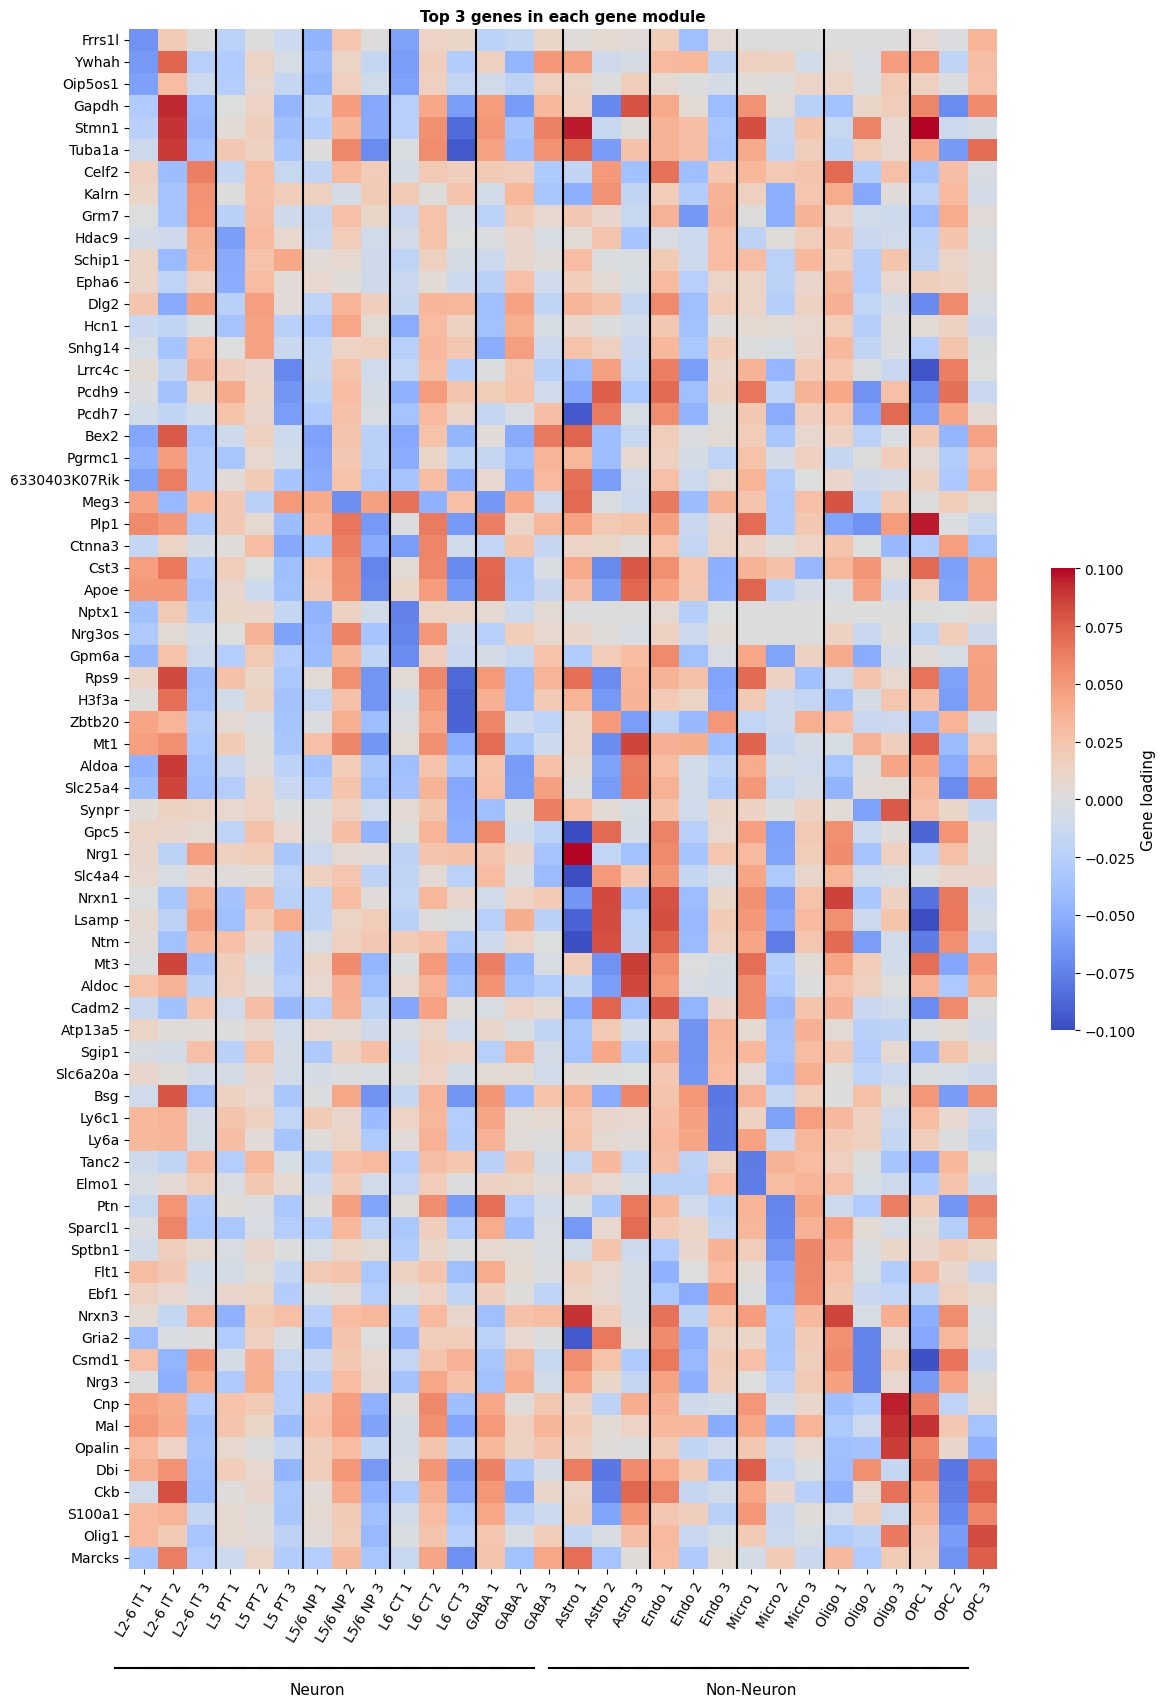

In [7]:
# ---------------------------
# Identify top genes per cell type
# ---------------------------
top_genes = []
for cell_type in cell_types_ordered:
    # Load the flipped x-loadings from PLS for the current cell type
    x_loadings = np.load(f'{date}/pls_pca/flipped/x_loadings_{cell_type}.npy')
    # Consider only the top 3 PLS components
    top_3_comp = x_loadings[0:3, :]
    # For each of the top 3 components, select the top N genes with highest absolute loading
    for c in range(0, 3):
        comp_df = pd.DataFrame({'comp': top_3_comp[c],
                                'comp_abs': abs(top_3_comp[c])},
                               index=overlap_genes).sort_values(by='comp_abs', ascending=False)
        top_genes.extend(comp_df.head(3).index)  # Collect top 3 genes across components

# ---------------------------
# Create a combined dataframe of top gene loadings across all cell types
# ---------------------------
to_plot = pd.DataFrame()
for cell_type in cell_types_ordered:
    # Load the flipped x-loadings for the current cell type
    x_loadings = np.load(f'{date}/pls_pca/flipped/x_loadings_{cell_type}.npy')
    
    # Format cell type name for plotting
    cell_type = cell_type.replace('-', '/').replace('_', ' ')
    if cell_type == 'L2/5 IT':
        cell_type = 'L2-6 IT'
    
    # Select top 3 components and only the previously identified top genes
    top_3_comp = pd.DataFrame(x_loadings[0:3, :].T,
                              index=overlap_genes,
                              columns=[f'{cell_type} 1', f'{cell_type} 2', f'{cell_type} 3']).loc[top_genes]
    
    # Concatenate the results into a single dataframe for plotting
    to_plot = pd.concat([to_plot, top_3_comp], axis=1)

# ---------------------------
# Plot heatmap of top gene loadings
# ---------------------------

# Plot heatmap of gene loadings
# drop_duplicates ensures each gene appears only once
plt.figure(figsize=(14, 20), dpi=100)
ax = sns.heatmap(
    to_plot.drop_duplicates(), # Drop duplicated genes 
    cmap='coolwarm',         
    vmax=0.1, vmin=-0.1,    # Symmetrical color bar
    cbar_kws={"shrink": 0.3, "label": r"Gene loading"}
)

# Customize colorbar font and label
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=10)
cbar.set_label(r"Gene loading", size=11)

# Add vertical lines to separate top 3 components per cell type
n_cols = to_plot.drop_duplicates().shape[1]
for i in range(3, n_cols, 3):
    ax.axvline(i, color='black', linewidth=1.5, linestyle='-')

# Improve layout and add title
ax.set_xticklabels(ax.get_xticklabels(), rotation=60, ha='right', rotation_mode='anchor')
plt.title('Top 3 genes in each gene module', fontweight='bold', fontsize=11)

# ---------------------------
# Highlight major groups of columns (Neuron vs Non-Neuron)
# ---------------------------

# First group of columns (Neuron)
highlight_cols_1 = range(0, 14)
y1 = to_plot.drop_duplicates().shape[0] + 4.5  # vertical position of bar
for col in highlight_cols_1:
    ax.plot([col - 0.5, col + 1], [y1, y1], color='black', linewidth=1.5, clip_on=False)
# Add group label
x1_center = (highlight_cols_1.start + highlight_cols_1.stop - 1) / 2
ax.text(x1_center, y1 + 1.3, 'Neuron', ha='center', va='bottom', fontsize=11)

# Second group of columns (Non-Neuron)
highlight_cols_2 = range(15, 29)
y2 = to_plot.drop_duplicates().shape[0] + 4.5
for col in highlight_cols_2:
    ax.plot([col - 0.5, col + 1], [y2, y2], color='black', linewidth=1.5, clip_on=False)
# Add group label
x2_center = (highlight_cols_2.start + highlight_cols_2.stop - 1) / 2
ax.text(x2_center, y2 + 1.3, 'Non-Neuron', ha='center', va='bottom', fontsize=11)

# Save figure as SVG
plt.savefig(f'../../Figures/psilocybin_mouse_pls/top_5_genes_all_cell_types_no_dup.svg', dpi=220, bbox_inches='tight')
plt.show()

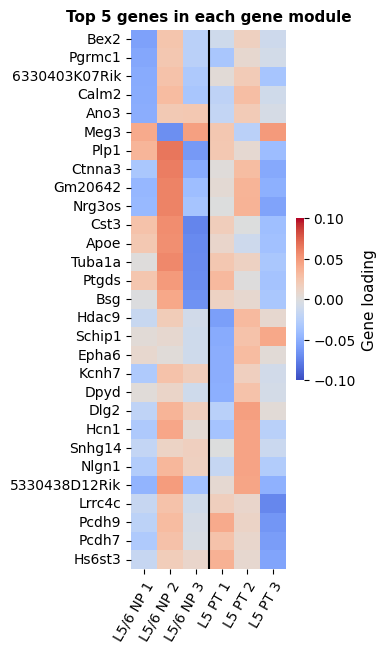

In [8]:
# ---------------------------
# Identify top genes for 'L5-6_NP' and 'L5_PT' neurons
# ---------------------------
top_genes = []
for cell_type in ['L5-6_NP', 'L5_PT']:
    # Load flipped x-loadings from PLS for the current cell type
    x_loadings = np.load(f'{date}/pls_pca/flipped/x_loadings_{cell_type}.npy')
    # Consider only the top 3 PLS components
    top_3_comp = x_loadings[0:3, :]
    
    # For each component, select the top N genes with highest absolute loading
    for c in range(0, 3):
        comp_df = pd.DataFrame({'comp': top_3_comp[c],
                                'comp_abs': abs(top_3_comp[c])},
                               index=overlap_genes).sort_values(by='comp_abs', ascending=False)
        top_genes.extend(comp_df.head(5).index)  # Collect top 5 genes

# ---------------------------
# Create a combined dataframe of top gene loadings for plotting
# ---------------------------
to_plot = pd.DataFrame()
for cell_type in ['L5-6_NP', 'L5_PT']:
    # Load flipped x-loadings
    x_loadings = np.load(f'{date}/pls_pca/flipped/x_loadings_{cell_type}.npy')

    # Format cell type name for plot labels
    cell_type = cell_type.replace('-', '/').replace('_', ' ')
    
    # Extract top 3 components and only the previously identified top genes
    top_3_comp = pd.DataFrame(x_loadings[0:3, :].T,
                              index=overlap_genes,
                              columns=[f'{cell_type} 1', f'{cell_type} 2', f'{cell_type} 3']).loc[top_genes]
    
    # Concatenate into a single dataframe for heatmap
    to_plot = pd.concat([to_plot, top_3_comp], axis=1)

# ---------------------------
# Plot heatmap of top gene loadings
# ---------------------------
plt.figure(figsize=(2.5, 7), dpi=100)
ax = sns.heatmap(to_plot.drop_duplicates(), cmap='coolwarm', vmax=0.1, vmin=-0.1, 
                 cbar_kws={"shrink": 0.3, "label": r"Gene loading"})

# Customize colorbar
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=10)
cbar.set_label(r"Gene loading", size=11)

# Add vertical lines to separate cell types
n_cols = to_plot.drop_duplicates().shape[1]
for i in range(3, n_cols, 3):
    ax.axvline(i, color='black', linewidth=1.5, linestyle='-')

# Improve layout and add title
ax.set_xticklabels(ax.get_xticklabels(), rotation=60, ha='right', rotation_mode='anchor')
plt.title('Top 5 genes in each gene module', fontweight='bold', fontsize=11)

# Save the figure as SVG
plt.savefig(f'../../Figures/psilocybin_mouse_pls/top_5_L5_PT_L5-6_NP_no_dup_squeezed.svg', dpi=220, bbox_inches='tight')
plt.show()


## Permutation test (component-level)

In [9]:
# ---------------------------
# Run PLS regression with permuted conditions for each cell type
# ---------------------------

for cell_type in cell_types:
    
    # Subset the gene expression dataframe for the current cell type
    subset_df = gene_exp_df.loc[gene_exp_df.subtype.str.contains(cell_type, case=False)]
    genes_df = subset_df[overlap_genes]
    print(cell_type)
    print(genes_df.shape)

    # Create numeric condition vector: 1 for 'PSY', -1 for SAL
    condition = pd.get_dummies(subset_df.condition, dtype=int)['PSY'].replace(0, -1).to_numpy()
    
    # Standardize the log-normalized matrix (towards zero mean, unit variance)
    genes_zscored = StandardScaler().fit_transform(genes_df)

    # ---------------------------
    # Dimensionality reduction using precomputed PCA
    # ---------------------------
    pca = joblib.load(f'{date}/pls_pca/pca_{cell_type}.gz')
    data_compressed = pca.transform(genes_zscored)  # Project gene data onto PCA components

    # ---------------------------
    # Run PLS regression on 100 permutations of the condition vector
    # ---------------------------
    for i in tqdm(range(0, 100)):
        np.random.seed(i) # Fix random seed for reproducibility
        np.random.shuffle(condition)  # Randomly permute condition labels

        # Fit PLS to PCA-compressed data and permuted condition
        pls = PLSRegression(n_components=20, scale=False)
        pls.fit(data_compressed, condition)

        # Save PLS model for this permutation
        joblib.dump(pls, f'{date}/pls_pca/permutations/pls_{cell_type}_{i}.gz')

        # Extract and save x- and y-loadings for the permuted PLS
        # Note: No need to flip/orient the PLS components at this step
        # Orientation will be applied later when aggregating results across permutations
        x_loadings = pca.inverse_transform(pls.x_loadings_.T)
        np.save(f'{date}/pls_pca/permutations/x_loadings_{cell_type}_{i}.npy', x_loadings)
        y_loadings = pls.y_loadings_
        np.save(f'{date}/pls_pca/permutations/y_loadings_{cell_type}_{i}.npy', y_loadings)


Astro
(13079, 8264)


100%|██████████| 100/100 [00:53<00:00,  1.86it/s]


Endo
(4559, 8264)


100%|██████████| 100/100 [00:17<00:00,  5.87it/s]


GABA
(944, 8264)


100%|██████████| 100/100 [00:18<00:00,  5.52it/s]


... (12 outputs left out)

OPC
(4809, 8264)


100%|██████████| 100/100 [00:32<00:00,  3.05it/s]


Oligo
(6314, 8264)


100%|██████████| 100/100 [00:30<00:00,  3.23it/s]


In [10]:
# ---------------------------
# Compute null distribution of PLS correlations across permutations
# ---------------------------

new_cols = ['comp_' + str(col) for col in range(1, 21)]

for cell_type in cell_types: 
    print(cell_type)
    
    # Initialize a DataFrame to store correlation values per component for all permutations
    dist = pd.DataFrame(index=new_cols)
    
    # Loop over all 100 permutation iterations
    for i in tqdm(range(0, 100)):
        # Load the PLS model fitted on the i-th permuted condition
        pls = joblib.load(f'{date}/pls_pca/permutations/pls_{cell_type}_{i}.gz')
        
        # Compute Pearson correlation between each PLS x-score and y-score
        Rs = np.array([pearsonr(X_coef, Y_coef)[0] 
                       for X_coef, Y_coef in zip(pls.x_scores_.T, pls.y_scores_.T)])
        
        # Store correlations for this iteration
        dist[f'it_{i}'] = Rs
    
    # Save the null distribution of correlations for this cell type
    dist.to_csv(f'{date}/pls_pca/permutations/{cell_type}_perm_dist.csv')


Astro


100%|██████████| 100/100 [00:13<00:00,  7.29it/s]


Endo


100%|██████████| 100/100 [00:07<00:00, 13.84it/s]


GABA


100%|██████████| 100/100 [00:04<00:00, 23.99it/s]


... (12 outputs left out)

OPC


100%|██████████| 100/100 [00:07<00:00, 12.95it/s]


Oligo


100%|██████████| 100/100 [00:07<00:00, 14.03it/s]


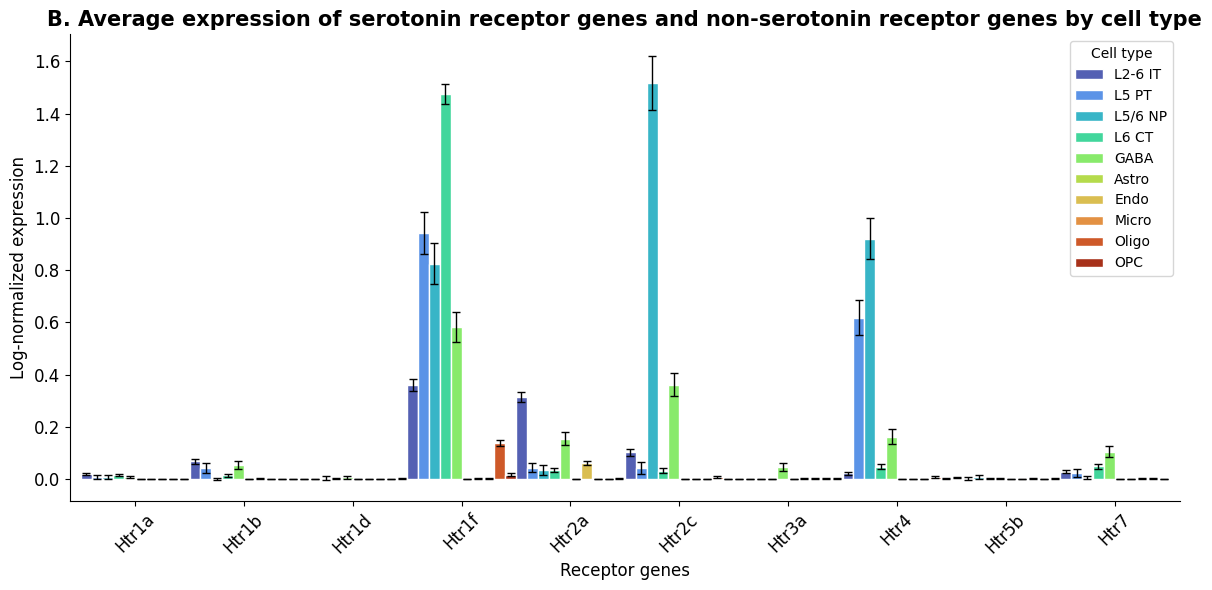

In [11]:
# Capitalize gene names for consistency
sero = [gene.capitalize() for gene in sero_mouse]

# Compute group-level statistics: mean, std, count per cell type
grouped = gene_exp_df.groupby('subtype')[sero].agg(['mean', 'std', 'count']).reset_index()

# Flatten MultiIndex columns generated by aggregation
grouped.columns = ['_'.join(col).strip('_') for col in grouped.columns.values]

# Clean and standardize cell type labels
grouped['subtype_'] = grouped['subtype'].str.replace('-', '/').str.replace('_', ' ')
grouped['subtype_'] = grouped['subtype_'].replace('L2/5 IT', 'L2-6 IT')
# Drop 'NFO'
grouped['subtype_'] = grouped['subtype_'].drop(np.where(grouped['subtype_']=='NFO')[0]).reset_index(drop=True)

# Reshape data to long format for plotting
# Identify mean, std, and count columns
mean_cols = [col for col in grouped.columns if col.endswith('mean')]
std_cols = [col for col in grouped.columns if col.endswith('std')]
count_cols = [col for col in grouped.columns if col.endswith('count')]

# Melt mean, std, and count into long format
df_mean = grouped.melt(id_vars='subtype_', value_vars=mean_cols, var_name='Gene', value_name='Mean')
df_mean['Gene'] = df_mean['Gene'].str.replace('_mean', '').str.capitalize()
df_std = grouped.melt(id_vars='subtype_', value_vars=std_cols, var_name='Gene', value_name='Std')
df_std['Gene'] = df_std['Gene'].str.replace('_std', '').str.capitalize()
df_count = grouped.melt(id_vars='subtype_', value_vars=count_cols, var_name='Gene', value_name='Count')
df_count['Gene'] = df_count['Gene'].str.replace('_count', '').str.capitalize()

# Merge mean, std, and count into a single dataframe
df_all = df_mean.merge(df_std, on=['subtype_', 'Gene'])
df_all = df_all.merge(df_count, on=['subtype_', 'Gene'])
df_all = df_all.rename(columns={'subtype_': 'Cell type'})

# Define cell type plotting order
order = [
 'L2-6 IT', 'L5 PT', 'L5/6 NP', 'L6 CT', 'GABA', 
 'Astro', 'Endo', 'Micro', 'Oligo', 'OPC']

# Plot barplot of mean expression with 95% confidence intervals
plt.figure(figsize=(12, 6), dpi=100)
ax = sns.barplot(
    data=df_all, x='Gene', y='Mean', hue='Cell type', hue_order=order, 
    palette='turbo', ci=None, width=1, linewidth=1, edgecolor="white"
)

# Compute 95% confidence interval for error bars
z = 1.96  # z-score for 95% CI
df_all['yerr'] = z * (df_all['Std'] / np.sqrt(df_all['Count']))

# Customize plot appearance
ax.spines[['right', 'top']].set_visible(False)
ax.set_ylabel('Log-normalized expression', fontsize=12)

# Overlay error bars on grouped bars
n_genes = len(df_all['Gene'].unique())
n_cell_types = len(order)
bar_width = 0.9 / n_cell_types
gene_order = df_all['Gene'].unique()

for j, gene in enumerate(gene_order):
    for k, cell in enumerate(order):
        subset = df_all[(df_all['Gene'] == gene) & (df_all['Cell type'] == cell)]
        if not subset.empty:
            group_width = 1
            bar_width = group_width / n_cell_types
            x = j + (k - (n_cell_types - 1) / 2) * bar_width
            y = subset['Mean'].values[0]
            yerr = subset['yerr'].values[0]
            ax.errorbar(x=x, y=y, yerr=yerr, fmt='none', c='black', capsize=3, linewidth=1)

# Final plot layout
plt.xlim(-0.6,9.6)
plt.xlabel('Receptor genes', fontsize=12)
plt.xticks(rotation=45, size=12)
plt.yticks(size=12)
plt.title('B. Average expression of serotonin receptor genes and non-serotonin receptor genes by cell type',
          fontweight='bold', fontsize=15)
plt.tight_layout()

# Save figure
plt.savefig('../../Figures/psilocybin_mouse_pls/average_exp_sero_Bagot_95_CI.svg', bbox_inches='tight', dpi=200)
plt.show()


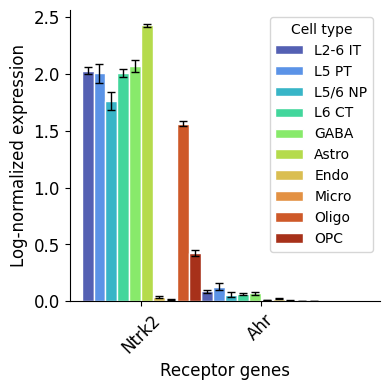

In [12]:
# Looking at non-serotonergic receptor expression
non_sero = []
non_sero.append('Ntrk2')
non_sero.append('Ahr')

# Compute group-level statistics: mean, std, count per cell type
grouped = gene_exp_df.groupby('subtype')[non_sero].agg(['mean', 'std', 'count']).reset_index()

# Flatten MultiIndex columns generated by aggregation
grouped.columns = ['_'.join(col).strip('_') for col in grouped.columns.values]

# Clean and standardize cell type labels
grouped['subtype_'] = grouped['subtype'].str.replace('-', '/').str.replace('_', ' ')
grouped['subtype_'] = grouped['subtype_'].replace('L2/5 IT', 'L2-6 IT')
# Drop 'NFO'
grouped['subtype_'] = grouped['subtype_'].drop(np.where(grouped['subtype_']=='NFO')[0]).reset_index(drop=True)

# Reshape data to long format for plotting
# Identify mean, std, and count columns
mean_cols = [col for col in grouped.columns if col.endswith('mean')]
std_cols = [col for col in grouped.columns if col.endswith('std')]
count_cols = [col for col in grouped.columns if col.endswith('count')]

# Melt mean, std, and count into long format
df_mean = grouped.melt(id_vars='subtype_', value_vars=mean_cols, var_name='Gene', value_name='Mean')
df_mean['Gene'] = df_mean['Gene'].str.replace('_mean', '').str.capitalize()
df_std = grouped.melt(id_vars='subtype_', value_vars=std_cols, var_name='Gene', value_name='Std')
df_std['Gene'] = df_std['Gene'].str.replace('_std', '').str.capitalize()
df_count = grouped.melt(id_vars='subtype_', value_vars=count_cols, var_name='Gene', value_name='Count')
df_count['Gene'] = df_count['Gene'].str.replace('_count', '').str.capitalize()

# Merge mean, std, and count into a single dataframe
df_all = df_mean.merge(df_std, on=['subtype_', 'Gene'])
df_all = df_all.merge(df_count, on=['subtype_', 'Gene'])
df_all = df_all.rename(columns={'subtype_': 'Cell type'})

# Define cell type plotting order
order = [
 'L2-6 IT', 'L5 PT', 'L5/6 NP', 'L6 CT', 'GABA', 
 'Astro', 'Endo', 'Micro', 'Oligo', 'OPC']

# Plot barplot of mean expression with 95% confidence intervals
plt.figure(figsize=(4, 4), dpi=100)
ax = sns.barplot(
    data=df_all, x='Gene', y='Mean', hue='Cell type', hue_order=order, 
    palette='turbo', ci=None, width=1, linewidth=1, edgecolor="white"
)

# Compute 95% confidence interval for error bars
z = 1.96  # z-score for 95% CI
df_all['yerr'] = z * (df_all['Std'] / np.sqrt(df_all['Count']))

# Customize plot appearance
ax.spines[['right', 'top']].set_visible(False)
ax.set_ylabel('Log-normalized expression', fontsize=12)

# Overlay error bars on grouped bars
n_genes = len(df_all['Gene'].unique())
n_cell_types = len(order)
bar_width = 0.9 / n_cell_types
gene_order = df_all['Gene'].unique()

for j, gene in enumerate(gene_order):
    for k, cell in enumerate(order):
        subset = df_all[(df_all['Gene'] == gene) & (df_all['Cell type'] == cell)]
        if not subset.empty:
            group_width = 1
            bar_width = group_width / n_cell_types
            x = j + (k - (n_cell_types - 1) / 2) * bar_width
            y = subset['Mean'].values[0]
            yerr = subset['yerr'].values[0]
            ax.errorbar(x=x, y=y, yerr=yerr, fmt='none', c='black', capsize=3, linewidth=1)

# Final plot layout
plt.xlim(-0.6,2)
plt.xlabel('Receptor genes', fontsize=12)
plt.xticks(rotation=45, size=12)
plt.yticks(size=12)
plt.tight_layout()

# Save figure
plt.savefig('../../Figures/psilocybin_mouse_pls/average_exp_Ntrk2_Ahr_Bagot_95_CI.svg', bbox_inches='tight', dpi=200)
plt.show()


L2-5_IT
L5_PT
L5-6_NP
L6_CT
GABA
Astro
Endo
Micro
Oligo
OPC


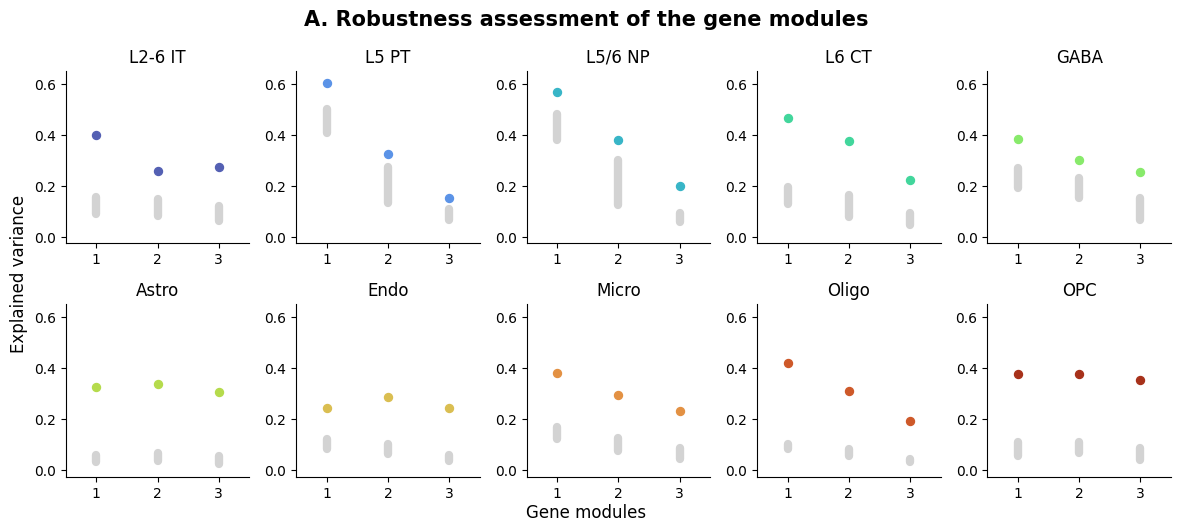

In [13]:
# Extract colors assigned to each cell type from previous plot
handles, labels = ax.get_legend_handles_labels()
cell_type_palette = {label: handle.get_facecolor() for label, handle in zip(labels, handles)}

# Set up subplots for robustness assessment across cell types
fig, axs = plt.subplots(2, 5, figsize=(12, 5.5), dpi=100)
new_cols = ['comp_' + str(col) for col in range(1, 21)]

# Loop over each cell type to plot permutation statistics and actual PLS correlations
for idx, cell_type in enumerate(cell_types_ordered):
    # Subset gene expression data
    subset_df = gene_exp_df.loc[gene_exp_df.subtype == cell_type]
    genes_df = subset_df[genes_list]
    print(cell_type)

    # Load permutation distribution of correlations for this cell type
    dist = pd.read_csv(f'{date}/pls_pca/permutations/{cell_type}_perm_dist.csv', index_col=0).loc[['comp_1', 'comp_2', 'comp_3']]

    # Compute 5th, 50th (median), and 95th percentiles for error bars
    low_b = list(np.percentile(dist, 5, axis=1))
    up_b = list(np.percentile(dist, 95, axis=1))
    median = list(np.percentile(dist, 50, axis=1))
    xt = range(len(new_cols[0:3]))  # X positions for plotting

    # Load actual PLS model and compute observed correlations for the first 3 components
    pls = joblib.load(f'{date}/pls_pca/pls_{cell_type}.gz')
    actual_Rs = np.array([pearsonr(X_coef, Y_coef)[0] for X_coef, Y_coef in zip(pls.x_scores_.T, pls.y_scores_.T)])

    # Standardize cell type labels for plotting
    if cell_type == 'L2-5_IT':
        cell_type='L2-6 IT'
    else:
        cell_type=cell_type.replace('-', '/').replace('_', ' ')

    # Prepare a DataFrame for plotting percentiles and observed correlations
    plot_df = pd.DataFrame(index=new_cols[0:3])
    plot_df['low_b'] = low_b
    plot_df['up_b'] = up_b
    plot_df['median'] = median
    plot_df['pearsonr'] = actual_Rs[0:3]

    # Determine subplot row and column
    row = idx // 5
    col = idx % 5

    # Plot error bars (5th-95th percentile) as vertical grey lines
    axs[row, col].plot((xt, xt), (plot_df.low_b, plot_df.up_b), lw=6, solid_capstyle='round', color='lightgrey', zorder=2)
    axs[row, col].set_ylim(-0.025, 0.65)

    # Overlay observed correlation values as colored points
    for k, actual_R in enumerate(actual_Rs[0:3]):
        axs[row, col].scatter(x=k, y=actual_R, s=33, color=cell_type_palette[cell_type], zorder=3)

    # Customize axes
    axs[row, col].set_xlim(-0.5, 2.5)
    axs[row, col].set_xticks(ticks=xt, rotation=0, labels=range(1, 4))
    axs[row, col].set_title(f'{cell_type}', fontsize=12)
    axs[row, col].grid(False)
    axs[row, col].spines[['right', 'top']].set_visible(False)

# Add figure-level labels and title
fig.supylabel('Explained variance')
fig.supxlabel('Gene modules', y=0.05)
fig.suptitle('A. Robustness assessment of the gene modules', fontweight="bold", fontsize=15)

# Save output plot
fig.tight_layout()
plt.savefig(f'../../Figures/psilocybin_mouse_pls/permutations.svg', dpi=200, bbox_inches='tight')
plt.show()
plt.close('all')


In [14]:
# Compute maximum discriminative capacity per cell type
max_Rs = []  # Store the maximum correlation per cell type

for cell_type in cell_types_ordered:
    # Subset gene expression data
    subset_df = gene_exp_df.loc[gene_exp_df.subtype == cell_type]
    genes_df = subset_df[genes_list]
    print(cell_type)
    
    # Load the precomputed PLS model for this cell type
    pls = joblib.load(f'{date}/pls_pca/pls_{cell_type}.gz')
    
    # Compute Pearson correlation between each PLS x-score and y-score
    actual_Rs = np.array([pearsonr(X_coef, Y_coef)[0] 
                          for X_coef, Y_coef in zip(pls.x_scores_.T, pls.y_scores_.T)])
    
    # Select the maximum correlation (component with highest discriminative capacity)
    top_Rs = max(actual_Rs)
    max_Rs.append(top_Rs)

L2-5_IT
L5_PT
L5-6_NP
L6_CT
GABA
Astro
Endo
Micro
Oligo
OPC


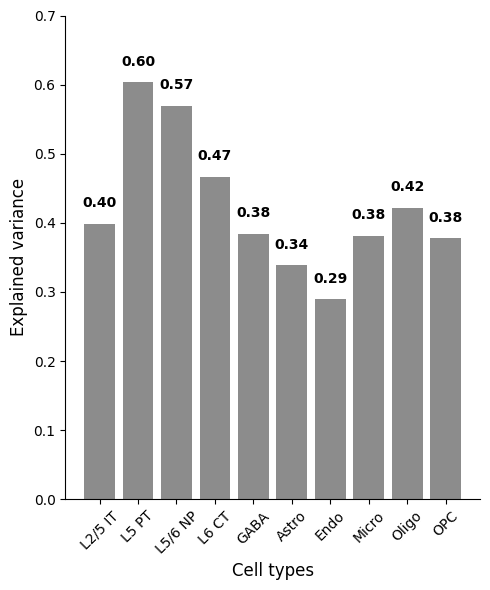

In [15]:
# Aesthetic settings
GREY12 = "#1f1f1f"
plt.rcParams["text.color"] = GREY12

# Plot setup
fig, ax = plt.subplots(figsize=(5, 6), dpi=100)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Plot bars in grey
cell_labels = [cell.replace('-', '/').replace('_', ' ') for cell in cell_types_ordered]
ax.bar(cell_labels, max_Rs, color='grey', alpha=0.9)

# Annotate values on top of each bar
for i, value in enumerate(max_Rs):
    ax.text(
        i, 
        value + 0.02,  # Slightly above the bar
        f"{value:.2f}",  # Format value to 2 decimal places
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight='bold',
        color='black'
    )

# Labels and aesthetics
ax.set_ylabel("Explained variance", fontsize=12)
ax.set_xlabel("Cell types", fontsize=12)
ax.set_ylim(0, 0.7)
# ax.grid(axis='y', linestyle='--', alpha=0.5)
# Only show bottom and left spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.xticks(rotation=45, size=10)

plt.tight_layout()
plt.savefig('../../Figures/psilocybin_mouse_pls/bar_plot.svg', dpi=200, bbox_inches='tight', pad_inches=0)
plt.show()


## Robustness of the genes

In [16]:
date = 'October_2025'
num_iterations = 1000  # Number of bootstrap iterations
num_cores = 60         # Number of parallel processes
b = 0                  # Starting iteration index

# Pre-split gene expression data by cell type to avoid repeated subsetting
subsets = {ct: gene_exp_df.loc[gene_exp_df.subtype == ct] for ct in cell_types}

# Function to perform one bootstrap iteration and save results
def fit_and_save(i, cell_type, log_file=f'{date}/bootstrap_parallel_log.txt'):
    with open(log_file, 'a') as f:
        f.write(f"Running iteration {i} for {cell_type}\n")

    # Paths for this bootstrap iteration
    pca_file = f'{date}/pls_pca/bootstrap/{cell_type}_pca_{i}.gz'
    pls_file = f'{date}/pls_pca/bootstrap/{cell_type}_pls_{i}.gz'
    x_loadings_file = f'{date}/pls_pca/bootstrap/{cell_type}_x_loadings_{i}.npy'
    y_loadings_file = f'{date}/pls_pca/bootstrap/{cell_type}_y_loadings_{i}.npy'

    # Check if all files exist (don't recompute this iteration if the script was interrupted)
    if all(os.path.exists(f) for f in [pca_file, pls_file, x_loadings_file, y_loadings_file]):
        # print(f"Bootstrap iteration {i} for {cell_type} already exists. Skipping computation.")
        return

    # Resample the data with replacement (bootstrap) using iteration i as random seed
    subset_df = subsets[cell_type]
    rand_df = sklearn.utils.resample(subset_df, replace=True, random_state=i).reset_index(drop=True)

    # Subset genes of interest and encode condition
    genes_df = rand_df[overlap_genes]
    condition = pd.get_dummies(rand_df.condition, dtype=int)['PSY'].replace(0, -1).to_numpy()

    # Standardize gene expression
    genes_zscored = StandardScaler().fit_transform(genes_df)

    # ---------------------------
    # Dimensionality reduction: PCA
    # ---------------------------
    pca = PCA(n_components=100, random_state=i)
    data_compressed = pca.fit_transform(genes_zscored)
    # Save PCA model for this iteration
    joblib.dump(pca, pca_file)

    # ---------------------------
    # Fit PLS regression on PCA-compressed data
    # ---------------------------
    pls = PLSRegression(n_components=20, scale=False)
    pls.fit(data_compressed, condition)
    # Save PLS model
    joblib.dump(pls, pls_file)

    # ---------------------------
    # Save component loadings
    # ---------------------------
    x_loadings = pca.inverse_transform(pls.x_loadings_.T)
    np.save(x_loadings_file, x_loadings)

    y_loadings = pls.y_loadings_
    np.save(y_loadings_file, y_loadings)

In [17]:
# ---------------------------
# Parallel execution
# ---------------------------
# For each cell type, run bootstrap iterations in parallel
# Using `num_cores` for parallelization
# Each iteration fits PCA + PLS and saves models/loadings
# ---------------------------

for cell_type in cell_types:
    results = Parallel(
        n_jobs=num_cores,
        temp_folder='/home/bic/chloes/pool8_z0/tmp',
        verbose=0
    )(
        delayed(fit_and_save)(i, cell_type) for i in tqdm(range(b, num_iterations))
    )


100%|██████████| 1000/1000 [02:05<00:00,  7.98it/s]


In [18]:
def match_comps(true_loadings, bts_loadings):
    """
    Match components from a bootstrap PLS model to a reference PLS solution.

    This function aligns the columns of `bts_loadings` (bootstrap PLS x-loadings) to
    `true_loadings` (original PLS x-loadings) by finding the most correlated components.
    It also orients each matched component to have the same sign as the reference.

    Parameters
    ----------
    true_loadings : np.ndarray
        The reference PLS x-loadings matrix (genes x components).
    bts_loadings : np.ndarray
        The bootstrap or secondary PLS x-loadings matrix (genes x components) to be matched.

    Returns
    -------
    pls_2_x_loadings : np.ndarray
        The aligned and sign-corrected x-loadings matrix of the bootstrap PLS.
        Columns correspond to the reference components.
    """

    n = true_loadings.shape[0]  # Number of features (genes)
    flag = []   # To store sign flips for each component

    # Compute correlation matrix between true and bootstrap loadings
    corr_mat = np.corrcoef(true_loadings, bts_loadings)
    corr_mat = corr_mat[:n, n:]  # Extract correlations between true and bootstrap components
    n_keep = n
    taken_ind = []  # Indices of bootstrap components already assigned

    # Loop over each reference component to find best matching bootstrap component
    for i_org_comp in range(n_keep):
        rhos = np.zeros((n_keep))
        for i_comp in range(n_keep):
            # Compute Pearson correlation between current true component and all bootstrap components
            rhos[i_comp], _ = pearsonr(
                true_loadings.T[:, i_org_comp],
                bts_loadings.T[:, i_comp])

        # Find the bootstrap component most correlated (by absolute value)
        good_comp_ind = np.argmax(abs(rhos))
        i = 1
        # If this component has already been assigned, take the next best
        while good_comp_ind in taken_ind:
            sorted_rhos = (-(abs(rhos))).argsort()  # Rank components by decreasing absolute correlation
            good_comp_ind = sorted_rhos[i]
            i += 1
        taken_ind.append(good_comp_ind)

        # Determine sign flip to align with reference component
        if rhos[good_comp_ind] < 0:
            flag.append(-1)
        else:
            flag.append(1)

    # Reorder and orient bootstrap loadings according to matched reference components
    pls_2_ind = taken_ind
    pls_2_x_loadings = bts_loadings.T[:, pls_2_ind]

    for i in range(len(flag)):
        pls_2_x_loadings[:, i] = flag[i] * pls_2_x_loadings[:, i]

    return pls_2_x_loadings


In [19]:
# ---------------------------
# Aggregate and align bootstrap x-loadings for each cell type
# ---------------------------

# Loop over each cell type
for cell_type in cell_types:

    print(cell_type)

    # Load the reference (original) PLS x-loadings for this cell type
    true_loadings = np.load(f'{date}/pls_pca/flipped/x_loadings_{cell_type}.npy')

    cell_stacked = []

    # Loop over all bootstrap iterations
    for i in tqdm(range(0,1000)):
        # Load bootstrap x-loadings
        bts_loadings = np.load(f'{date}/pls_pca/bootstrap/{cell_type}_x_loadings_{i}.npy')

        # Align bootstrap components to the reference components
        bts_loadings = match_comps(true_loadings, bts_loadings)
        # bts_loadings.shape = (8264, 20)

        # Store bootstrap loadings
        cell_stacked.append(bts_loadings)

    # Stack arrays in sequence horizontally (column wise) and saved stacked numpy array
    np.save(f'{date}/pls_pca/bootstrap/{cell_type}_bts_dist_flipped.npy', np.hstack(cell_stacked))


Astro


100%|██████████| 1000/1000 [01:03<00:00, 15.71it/s]


Endo


100%|██████████| 1000/1000 [01:05<00:00, 15.16it/s]


GABA


100%|██████████| 1000/1000 [01:04<00:00, 15.40it/s]


... (12 outputs left out)

OPC


100%|██████████| 1000/1000 [01:04<00:00, 15.45it/s]


Oligo


100%|██████████| 1000/1000 [01:03<00:00, 15.77it/s]


In [20]:
# Compute robust/significant genes per component using bootstrap PLS distributions
for cell_type in cell_types:

    print(cell_type)

    # Load reference PLS x-loadings for this cell type
    true_loadings = np.load(f'{date}/pls_pca/flipped/x_loadings_{cell_type}.npy')

    # Load bootstrap distribution of aligned x-loadings
    arr = np.load(f'{date}/pls_pca/bootstrap/{cell_type}_bts_dist_flipped.npy')

    # Convert to DataFrame for easier indexing (genes × (components × iterations))
    cell_df = pd.DataFrame(arr, index=overlap_genes)

    # Define confidence interval percentiles
    low_b = 2.5
    top_b = 97.5

    all_robust = []  # To store all significant genes for all components
    top_robust = []  # To store top 100 genes per component

    # Iterate through the first 3 PLS components
    for c in tqdm(range(0,3)):

        # Select bootstrap loadings corresponding to this component across all iterations
        comp_loadings = cell_df.iloc[:, c::20]

        # Compute percentile bounds (2.5th and 97.5th) for each gene
        stats_df = pd.DataFrame(
            np.percentile(comp_loadings, [low_b, top_b], axis=1).T,
            index=overlap_genes,
            columns=['low', 'top']
        ).round(3)

        # Add reference loadings and component index
        stats_df['Component'] = c+1
        stats_df['Loading'] = true_loadings[c, :]

        # Determine whether gene is significant: CI does not cross zero
        stats_df['Significant'] = np.where(
            ((stats_df['low']>0) & (stats_df['top']>0)) | ((stats_df['low']<0) & (stats_df['top']<0)),
            True, False
        )

        # Keep only significant genes and sort by absolute loading
        sign_df = stats_df.loc[stats_df.Significant==True].sort_values(by='Loading')
        sign_df['abs'] = abs(sign_df['Loading'])
        sign_df = sign_df.sort_values('abs', ascending=False)

        # Rename CI columns for clarity
        sign_df = sign_df.rename(columns={
            'low':'Lower bound CI (2.5%)',
            'top':'Upper bound CI (97.5%)'
        })

        # Append to lists
        all_robust.append(sign_df)              # All significant genes
        top_robust.append(sign_df.head(100))    # Top 100 genes

    # Save results per cell type
    pd.concat(all_robust).to_csv(f'{date}/supplementary_tables/{cell_type}_all_robust_genes.csv')
    pd.concat(top_robust).to_csv(f'{date}/supplementary_tables/{cell_type}_top_100_robust_genes.csv')

Astro


100%|██████████| 3/3 [00:00<00:00,  7.11it/s]


Endo


100%|██████████| 3/3 [00:00<00:00,  7.41it/s]


GABA


100%|██████████| 3/3 [00:00<00:00,  7.21it/s]


... (12 outputs left out)

OPC


100%|██████████| 3/3 [00:00<00:00,  6.92it/s]


Oligo


100%|██████████| 3/3 [00:00<00:00,  7.02it/s]


In [21]:
# ---------------------------
# Combine individual CSVs into Excel workbooks
# ---------------------------

# Save top 100 robust genes for all cell types in a single Excel file
output_file = f"{date}/supplementary_tables/top_100_robust_genes.xlsx"

with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
    for cell_type in cell_types:
        # Read the per-cell-type CSV of top 100 robust genes
        csv_path = f"{date}/supplementary_tables/{cell_type}_top_100_robust_genes.csv"
        df = pd.read_csv(csv_path)

        # Write to Excel sheet named after the cell type (truncate to 31 chars for Excel limits)
        df.to_excel(writer, sheet_name=cell_type[:31], index=False)

print(f"Excel file saved as {output_file}")

# Save all significant robust genes for all cell types in a separate Excel file
output_file = f"{date}/supplementary_tables/all_robust_genes.xlsx"

with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
    for cell_type in cell_types:
        # Read the per-cell-type CSV of all robust genes
        csv_path = f"{date}/supplementary_tables/{cell_type}_all_robust_genes.csv"
        df = pd.read_csv(csv_path)

        # Write to Excel sheet named after the cell type (truncate to 31 chars)
        df.to_excel(writer, sheet_name=cell_type[:31], index=False)

print(f"Excel file saved as {output_file}")

Excel file saved as October_2025/supplementary_tables/top_100_robust_genes.xlsx
Excel file saved as October_2025/supplementary_tables/all_robust_genes.xlsx


## GSEA

### MitoCarta 3.0

In [22]:
def filter_mitocarta_hits(nz_gsea_df_sig):
    """
    Filter GSEA hits to remove subcategories and simplify terms.

    Parameters
    ----------
    nz_gsea_df_sig : pd.DataFrame
        DataFrame with at least 'Term' and 'NES' columns from GSEA results.

    Returns
    -------
    hits_df : pd.DataFrame
        Filtered DataFrame with unique terms and their corresponding NES values.
    """
    terms = []
    nes = []
    hits_df = pd.DataFrame()
    
    # Clean up GO terms (replace '.' and '_' with more readable format)
    for hits in range(len(nz_gsea_df_sig)):
        go_1 = nz_gsea_df_sig.Term[hits].replace('.', ' : ').replace('_',' ')
        terms.append(go_1)
        nes.append(nz_gsea_df_sig.NES[hits])
    
    # Filter out subcategories (skip terms that are contained in previous term)
    filtered_terms = []
    filtered_nes = []
    for i in range(len(terms)):
        if i == 0:
            filtered_terms.append(terms[0])
            filtered_nes.append(nes[0])
        elif terms[i] in terms[i-1]:
            continue
        else:
            filtered_terms.append(terms[i])
            filtered_nes.append(nes[i])

    hits_df['Term'] = filtered_terms
    hits_df['NES'] = filtered_nes
    return hits_df


def roman_to_arabic(text):
    """
    Replace all Roman numerals in a text with Arabic numerals.

    Parameters
    ----------
    text : str
        Input string containing Roman numerals.

    Returns
    -------
    str
        Text with Roman numerals converted to Arabic numerals.
    """
    pattern = r'\b[IVXLCDM]+\b'  # Regex for Roman numerals
    
    def replace(match):
        return str(fromRoman(match.group(0)))  # Convert each match

    return re.sub(pattern, replace, text)


def pruning(text):
    """
    Replace certain patterns in text to a standardized format.

    Steps:
    1. 'Complex {k}' → 'Complex_{k}'
    2. '{k} subunits' → '{k}_subunits'

    Parameters
    ----------
    text : str
        Input text to standardize.

    Returns
    -------
    str
        Standardized text with underscores for easier parsing.
    """
    # Step 1
    text_step1 = re.sub(r'Complex\s+(\d+)', r'Complex_\1', text)
    # Step 2
    text_step2 = re.sub(r'(\d+)\s+subunits', r'\1_subunits', text_step1)
    return text_step2


def back_to_roman(vocabulary):
    """
    Convert numbers in text (including patterns like 'Complex_3') back to Roman numerals.

    Parameters
    ----------
    vocabulary : list of str
        List of strings containing numbers to convert.

    Returns
    -------
    reversed_vocabulary : list of str
        Text with numbers converted back to Roman numerals.
    """
    reversed_vocabulary = []
    for items in vocabulary:
        subitems = []
        for word in items.split(' '):
            if re.match(r'\d+', word) or re.match(r'.*_\d+', word):
                parts = word.split('_')
                roman_parts = [toRoman(int(part)) if part.isdigit() else part for part in parts]
                subitems.append('_'.join(roman_parts))
            else:
                subitems.append(word)
        reversed_vocabulary.append(' '.join(subitems))
    return reversed_vocabulary

In [23]:
def mito_gsea2(pathh, loading, gene_list, comp, pval, save=False):
    """
    Perform pre-ranked GSEA on a set of genes using their PLS loadings and filter significant mitochondrial pathways.

    Parameters
    ----------
    pathh : str
        Path to save results if save=True.
    loading : array-like
        PLS loadings for genes, used to rank them.
    gene_list : list of str
        List of gene names corresponding to the loadings.
    comp : int
        Component index (for labeling the output).
    pval : float
        FDR q-value threshold for significance.
    save : bool, default False
        Whether to append the results to a text file.

    Returns
    -------
    nz_gsea_df_sig : pd.DataFrame
        DataFrame of significantly enriched mitochondrial pathways for the given component.
    """
    # Run pre-ranked GSEA using the MitoPathways3.0.gmt gene sets
    nz_res = gp.prerank(
        rnk=pd.DataFrame({'genes': gene_list, 'PLS_weights': loading}),
        gene_sets='MitoPathways3.0.gmt',
        min_size=5,
        max_size=len(gene_list),
        outdir=None,
        permutation_num=1000,
        seed=42,
        verbose=False
    )

    # Extract GSEA results
    nz_gsea_df = nz_res.res2d

    # Sort results by enrichment score
    nz_gsea_df = nz_gsea_df.sort_values(by='ES')

    # Keep only significantly enriched pathways
    nz_gsea_df_sig = nz_gsea_df[nz_gsea_df["FDR q-val"] < pval].reset_index(drop=True)

    # Optionally save summary to text file
    if save:
        with open(f'{pathh}/gsea_{cell_type}_{pval}.txt', 'a') as f:
            f.write(f'PLS-C {comp+1} \n')
            f.write(f'Number of significantly enriched pathways: {nz_gsea_df_sig.Term.values.shape[0]} \n')
            f.write('Pathways \n')
            f.write(f'{nz_gsea_df_sig.Term.values} \n\n')

    return nz_gsea_df_sig

In [24]:
def plot_network(nz_gsea_df_sig):
    """
    Build and plot a network of significantly enriched pathways based on their overlaps.

    Parameters
    ----------
    nz_gsea_df_sig : pd.DataFrame
        DataFrame of significant GSEA pathways with columns such as 'Term', 'NES', and 'Hits_ratio'.

    Returns
    -------
    G : networkx.Graph
        The network graph object representing pathway relationships.
    fig : matplotlib.figure.Figure
        The figure object containing the plotted network.
    ax : matplotlib.axes.Axes
        The axes object for the plotted network.
    """
    
    # Compute nodes and edges for the enrichment network
    nodes, edges = enrichment_map(nz_gsea_df_sig)

    # Build a graph from the edges DataFrame
    G = nx.from_pandas_edgelist(
        edges,
        source='src_idx',
        target='targ_idx',
        edge_attr=['jaccard_coef', 'overlap_coef', 'overlap_genes']
    )

    # Initialize figure
    fig, ax = plt.subplots(figsize=(4, 3), dpi=200)
    fig.tight_layout()
    fig.subplots_adjust(right=1.25)

    # Initialize node coordinates using a spiral layout
    pos = nx.layout.spiral_layout(G)

    # Ensure NES values are numeric for coloring
    nodes['NES'] = pd.to_numeric(nodes['NES'], errors='coerce')
    nodes = nodes.dropna(subset=['NES'])

    # Normalize NES values for color mapping
    norm = plt.Normalize(vmin=nodes.NES.min()-0.5, vmax=nodes.NES.max())
    cmap = plt.cm.Blues
    node_colors = cmap(norm(nodes.NES.values))

    # Draw nodes: size proportional to Hits_ratio, color fixed (turquoise)
    nx.draw_networkx_nodes(
        G,
        pos=pos,
        edgecolors='#CDDBD4',
        node_color='turquoise',
        node_size=list(nodes.Hits_ratio * 1000)
    )

    # Position node labels relative to the centroid of each node's neighbors
    label_ratio = 1.0 / 25.0
    pos_labels = {}
    for aNode in G.nodes():
        x, y = pos[aNode]
        N = G[aNode]  # neighbors
        cx = sum(pos[n][0] for n in N) / len(pos)
        cy = sum(pos[n][1] for n in N) / len(pos)
        slopeX = -abs(x - cx)
        slopeY = -abs(y - cy)
        pos_labels[aNode] = (x + slopeX * label_ratio - 0.1, y + slopeY * label_ratio - 0.25)

    # Draw node labels
    nx.draw_networkx_labels(
        G,
        pos=pos_labels,
        font_size=10,
        labels=nodes.Term.to_dict(),
        horizontalalignment='right',
        verticalalignment='top'
    )

    # Draw edges: width proportional to Jaccard coefficient
    edge_weight = nx.get_edge_attributes(G, 'jaccard_coef').values()
    nx.draw_networkx_edges(
        G,
        pos=pos,
        width=list(map(lambda x: x*10, edge_weight)),
        edge_color='#CDDBD4'
    )

    # Return both the graph and the plot objects
    return G, fig, ax


In [25]:
date = 'October_2025'
folder = f'MitoCarta'
new_path = f'{date}/{folder}'
os.makedirs(new_path, exist_ok=True)

for cell_type in cell_types:
    print(cell_type)
    
    # Load the PLS model for this cell type
    pls = joblib.load(f'{date}/pls_pca/pls_{cell_type}.gz')

    # Subset gene expression 
    subset_df = gene_exp_df.loc[gene_exp_df.subtype==cell_type]

    # Prepare the condition vector: +1 for PSY, -1 for SAL
    condition = pd.get_dummies(subset_df.condition, dtype=int)['PSY'].replace(0,-1).to_numpy()

    # Compute Pearson correlations between PLS component scores and condition
    actual_Rs = np.array([pearsonr(X_coef, Y_coef)[0] 
                          for X_coef, Y_coef in zip(pls.x_scores_.T, pls.y_scores_.T)])

    # Load the oriented (flipped) X loadings
    x_loadings = np.load(f'{date}/pls_pca/flipped/x_loadings_{cell_type}.npy')

    # Use uppercase gene symbols for consistency with MitoCarta
    genes = [gene.upper() for gene in overlap_genes]
    pval = 0.05

    # DataFrame to store pathway hits across components
    cell_type_paths_df = pd.DataFrame()

    # Iterate over first 3 PLS components
    for comp in tqdm(range(0,3)):

        # Only consider components with at least modest correlation with condition
        if actual_Rs[comp] > 0.10:

            # Extract loadings for this component
            loadings = x_loadings[comp,:]

            # Perform GSEA using the mitochondrial pathways gene set
            hits_df = pd.DataFrame() # Empty dataframe to store NES for significant hits
            nz_gsea_df_sig = mito_gsea2(new_path, loadings, genes, comp, pval, save=False)
            nz_gsea_df_sig.to_csv(f'{new_path}/{cell_type}_hits_comp_{comp+1}_pval_{pval}_.csv') # Save significant pathways
            hits = nz_gsea_df_sig[['Term', 'NES']].copy()
            hits_df[f'comp_{comp+1}'] = hits.Term
            # Concatenate component-level hits into cell-type-level DataFrame
            cell_type_paths_df = pd.concat([cell_type_paths_df,hits_df.T])
        else:
            continue

    # Save the final table of significant mitochondrial pathways for this cell type
    cell_type_paths_df.to_csv(f'{date}/{folder}/{cell_type}_hits_pval_{pval}_.csv')


Astro


  0%|          | 0/3 [00:00<?, ?it/s]2025-10-20 22:16:06,948 [WARNING] Duplicated values found in preranked stats: 3.73% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
 33%|███▎      | 1/3 [00:00<00:01,  1.28it/s]2025-10-20 22:16:07,730 [WARNING] Duplicated values found in preranked stats: 3.73% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
 67%|██████▋   | 2/3 [00:01<00:00,  1.32it/s]2025-10-20 22:16:08,465 [WARNING] Duplicated values found in preranked stats: 3.73% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
100%|██████████| 3/3 [00:02<00:00,  1.34it/s]


Endo


  0%|          | 0/3 [00:00<?, ?it/s]2025-10-20 22:16:09,530 [WARNING] Duplicated values found in preranked stats: 7.91% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
 33%|███▎      | 1/3 [00:00<00:01,  1.39it/s]2025-10-20 22:16:10,250 [WARNING] Duplicated values found in preranked stats: 7.95% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
 67%|██████▋   | 2/3 [00:01<00:00,  1.43it/s]2025-10-20 22:16:10,938 [WARNING] Duplicated values found in preranked stats: 7.78% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
100%|██████████| 3/3 [00:02<00:00,  1.42it/s]


GABA


  0%|          | 0/3 [00:00<?, ?it/s]2025-10-20 22:16:11,835 [WARNING] Duplicated values found in preranked stats: 5.70% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
 33%|███▎      | 1/3 [00:00<00:01,  1.36it/s]2025-10-20 22:16:12,574 [WARNING] Duplicated values found in preranked stats: 5.75% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
 67%|██████▋   | 2/3 [00:01<00:00,  1.37it/s]2025-10-20 22:16:13,300 [WARNING] Duplicated values found in preranked stats: 5.70% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
100%|██████████| 3/3 [00:02<00:00,  1.37it/s]


... (12 outputs left out)

OPC


  0%|          | 0/3 [00:00<?, ?it/s]2025-10-20 22:16:28,500 [WARNING] Duplicated values found in preranked stats: 5.46% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
 33%|███▎      | 1/3 [00:00<00:01,  1.39it/s]2025-10-20 22:16:29,221 [WARNING] Duplicated values found in preranked stats: 5.41% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
 67%|██████▋   | 2/3 [00:01<00:00,  1.36it/s]2025-10-20 22:16:29,964 [WARNING] Duplicated values found in preranked stats: 5.38% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
100%|██████████| 3/3 [00:02<00:00,  1.36it/s]


Oligo


  0%|          | 0/3 [00:00<?, ?it/s]2025-10-20 22:16:31,080 [WARNING] Duplicated values found in preranked stats: 11.94% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
 33%|███▎      | 1/3 [00:00<00:01,  1.34it/s]2025-10-20 22:16:31,825 [WARNING] Duplicated values found in preranked stats: 11.91% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
 67%|██████▋   | 2/3 [00:01<00:00,  1.35it/s]2025-10-20 22:16:32,561 [WARNING] Duplicated values found in preranked stats: 11.86% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
100%|██████████| 3/3 [00:02<00:00,  1.36it/s]


L5-6_NP


  0%|          | 0/1 [00:00<?, ?it/s]2025-10-20 22:16:33,303 [WARNING] Duplicated values found in preranked stats: 14.32% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


      Name             Term        ES       NES NOM p-val FDR q-val  \
0  prerank  OXPHOS subunits  0.725967  1.617272   0.00103  0.028643   
1  prerank        Complex I  0.737712  1.573599   0.00104  0.043495   
2  prerank      CI subunits  0.801021  1.648614       0.0  0.031825   

  FWER p-val  Tag %  Gene %                                         Lead_genes  
0      0.051  15/22  18.04%  NDUFC2;NDUFA11;COX5A;NDUFB5;NDUFB8;ATP5MD;NDUF...  
1      0.108  11/16  13.32%  NDUFC2;NDUFA11;NDUFB5;NDUFB8;NDUFB6;NDUFS4;NDU...  
2      0.029  10/13  12.19%  NDUFC2;NDUFA11;NDUFB5;NDUFB8;NDUFB6;NDUFS4;NDU...  


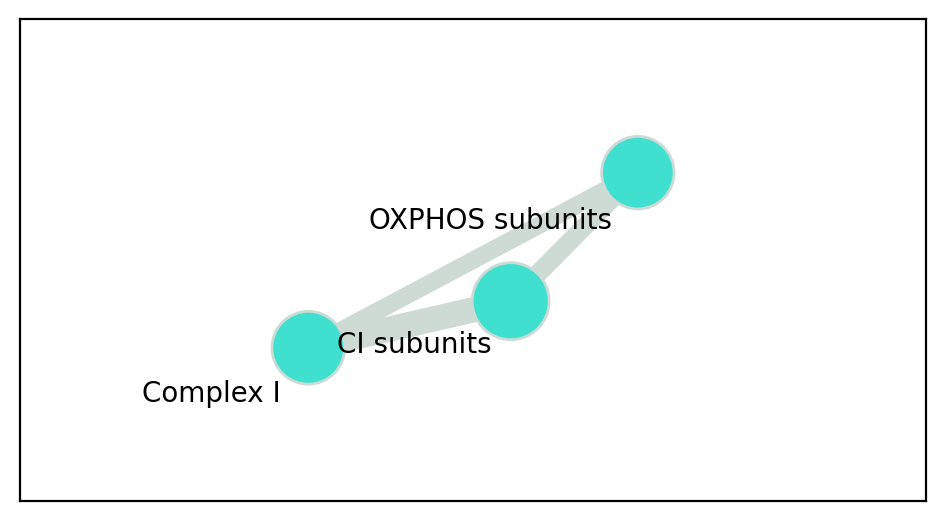

100%|██████████| 1/1 [00:00<00:00,  1.14it/s]


In [26]:
for cell_type in ['L5-6_NP']:  # Run only for a single cell type
    print(cell_type)

    # Load oriented X loadings
    x_loadings = np.load(f'{date}/pls_pca/flipped/x_loadings_{cell_type}.npy')

    # Prepare gene list in uppercase
    genes = [gene.upper() for gene in overlap_genes]
    pval = 0.05

    # DataFrame to store significant pathway hits
    cell_type_paths_df = pd.DataFrame()

    # Iterate over the PLS components of interest (here, only one component)
    for comp in tqdm(range(1,2)):

        # Extract loadings for the component
        loadings = x_loadings[comp,:]

        # Run mitochondrial GSEA
        nz_gsea_df_sig = mito_gsea2(new_path, loadings, genes, comp, pval, save=True)

        # Clean pathway labels: keep last segment after "." and replace underscores
        cut_term = [term.split(".")[-1].replace('_',' ') for term in nz_gsea_df_sig['Term']]
        nz_gsea_df_sig['Term'] = cut_term

        # Print significant pathways
        print(nz_gsea_df_sig)

        # Generate and plot the enrichment network
        G, fig, ax = plot_network(nz_gsea_df_sig)

        # Add margins and save the figure
        plt.margins(0.75)
        plt.savefig(f'../../Figures/psilocybin_mouse_pls/mitocarta_gsea_{cell_type}.svg', bbox_inches='tight')
        plt.show()
        plt.close('all')


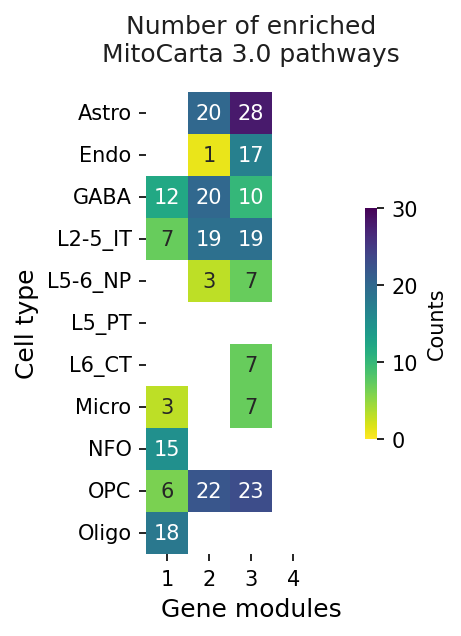

In [27]:
# ---------------------------
# Count the number of significant mitochondrial pathway hits **per PLS component** and cell type
# ---------------------------

date = 'October_2025'
folder = f'MitoCarta'
new_path = f'{date}/{folder}'
# os.makedirs(new_path, exist_ok=True)
pval = 0.05

# Initialize a DataFrame to store counts for all cell types
mito_hits_cell_df = pd.DataFrame()

# Loop over each cell type
for cell_type in cell_types:

    # Load previously saved significant mitochondrial hits for this cell type
    paths_df = pd.read_csv(f'{new_path}/{cell_type}_hits_pval_{pval}_.csv', index_col=0)
    mito_hits_df = pd.DataFrame()

    # Iterate over the first 3 PLS components
    for i in range(0,3):
        row = f'comp_{i}'
        if row in paths_df.index:
            # Count the number of non-missing pathway hits for this component
            row_sr = paths_df.loc[row].dropna().copy()
            N_hits = len(row_sr)
            # Store the count (or NaN if no hits)
            mito_hits_df[row] = [N_hits if N_hits>0 else np.nan]
        else:
            mito_hits_df[row] = [np.nan]

    # Set the cell type as the index and append to the main DataFrame
    mito_hits_df.index = [cell_type]
    mito_hits_cell_df = pd.concat([mito_hits_cell_df, mito_hits_df], axis=0) 

# Save the table of counts of significant mitochondrial hits for all cell types
mito_hits_cell_df.to_csv(f'{new_path}/all_hits_counts_20_pval_{pval}_.csv')


# ---------------------------
# Count significant mitochondrial pathway hits **per cell type** and visualize as a heatmap
# ---------------------------

# Initialize a DataFrame to store counts for all cell types
mito_hits_cell_df = pd.DataFrame()

# Loop over each cell type
for cell_type in cell_types:

    # Load previously saved significant mitochondrial hits for this cell type
    paths_df = pd.read_csv(f'{new_path}/{cell_type}_hits_pval_{pval}_.csv', index_col=0)
    mito_hits_df = pd.DataFrame()

    # Iterate over the first 5 PLS components
    for i in range(1,6):
        row = f'comp_{i}'
        if row in paths_df.index:
            # Count the number of non-missing pathway hits for this component
            row_sr = paths_df.loc[row].dropna().copy()
            N_hits = len(row_sr)
            mito_hits_df[row] = [N_hits if N_hits>0 else np.nan]
        else:
            mito_hits_df[row] = [np.nan]

    # Set the cell type as the index and append to the main DataFrame
    mito_hits_df.index = [cell_type]
    mito_hits_cell_df = pd.concat([mito_hits_cell_df, mito_hits_df], axis=0)   

# Save the summary table to CSV
mito_hits_cell_df.to_csv(f'{new_path}/all_hits_counts_20_pval_{pval}_.csv')

# Plot heatmap
plt.figure(figsize=(4,4), dpi=150)
sns.heatmap(
    mito_hits_cell_df.round(2), 
    cmap="viridis_r", 
    annot=True, 
    square=True, 
    vmin=0, vmax=30,
    cbar_kws={"shrink": 0.5, "pad":0.02, 'label': 'Counts'},
    xticklabels=range(1,5),
    fmt='g'
)
plt.title('Number of enriched\nMitoCarta 3.0 pathways', fontsize=12, pad=15)
plt.ylabel('Cell type', fontsize=12)
plt.xlabel('Gene modules', fontsize=12)
plt.savefig(f'../../Figures/psilocybin_mouse_pls/mitocarta_enriched_paths_counts_pval_{pval}.svg', dpi=200, bbox_inches='tight')
plt.show()

### Gene ontology

In [28]:
def gsea2(pathh, loading, gene_list, comp, pval, set, save=False):
    """
    Perform GSEA (Gene Set Enrichment Analysis) using pre-ranked gene weights from a PLS component.

    Parameters
    ----------
    pathh : str
        Path where results may be saved.
    loading : array-like
        Gene weights from a PLS component used for ranking.
    gene_list : list of str
        List of gene names corresponding to the loadings.
    comp : int
        Index of the PLS component being analyzed.
    pval : float
        FDR q-value threshold to define significant pathways.
    set : str or file
        Gene set database (e.g., GO, MitoCarta, KEGG) for enrichment analysis.
    save : bool, default False
        Whether to save a summary of significant pathways to a text file.

    Returns
    -------
    nz_gsea_df_sig : pd.DataFrame
        DataFrame of significantly enriched pathways with FDR < pval, sorted by enrichment score.

    Notes
    -----
    This function uses `gseapy.prerank` to perform enrichment analysis on ranked gene weights.
    Optionally, it saves a summary of significant pathways to a text file, appending the number
    of hits and their names.
    """
    nz_res = gp.prerank(
        rnk=pd.DataFrame({'genes': gene_list, 'PLS_weights': loading}),
        gene_sets=set,
        min_size=5,
        max_size=len(gene_list),
        outdir=None,
        permutation_num=1000,
        seed=42,
        verbose=False
    )
    
    # Extract results table and sort by enrichment score
    nz_gsea_df = nz_res.res2d.sort_values(by='ES')
    
    # Filter for significant pathways by FDR q-value
    nz_gsea_df_sig = nz_gsea_df[nz_gsea_df["FDR q-val"] < pval].reset_index(drop=True)
    
    # Optionally save summary to file
    if save:
        with open(f'{pathh}/gsea_{cell_type}_{pval}.txt', 'a') as f:
            f.write(f'PLS-C {comp+1} \n')
            f.write(f'Number of significantly enriched pathways: {nz_gsea_df_sig.Term.values.shape[0]} \n')
            f.write('Pathways \n')
            f.write(f'{nz_gsea_df_sig.Term.values} \n\n')

    return nz_gsea_df_sig


def summarize_paths(nz_gsea_df_sig, comp):
    """
    Summarize GSEA pathways by grouping related terms and cleaning pathway names.

    Parameters
    ----------
    nz_gsea_df_sig : pd.DataFrame
        DataFrame of significant pathways from GSEA.
    comp : int
        Index of the PLS component being summarized.

    Returns
    -------
    df : pd.DataFrame
        DataFrame with a single row corresponding to the component, containing
        grouped and cleaned pathway names.

    Notes
    -----
    - Iterates over significant pathways and groups related terms based on string similarity.
    - Removes numeric characters, parentheses, and colons from pathway names.
    - Helps reduce redundancy in pathway lists by grouping similar or overlapping terms.
    """
    df = pd.DataFrame()
    paths = []

    # Iterate over all significant pathways
    for hits in range(len(nz_gsea_df_sig)):
        grp = []
        go_1 = nz_gsea_df_sig.Term[hits].split(' ')[-1]

        # Skip if already grouped
        if go_1 in " ".join(str(element) for element in paths):
            continue

        grp.append(nz_gsea_df_sig.Term[hits])

        # Compare with subsequent pathways to find overlaps
        for counter in range(1, len(nz_gsea_df_sig)-hits):
            go_2 = nz_gsea_df_sig.Term[hits+counter].split(' ')[-1]
            if go_2 in " ".join(str(element) for element in paths):
                continue
            elif go_1[:-2] == go_2[:-2]:
                grp.append(nz_gsea_df_sig.Term[hits+counter])

        paths.append(grp)

    # Clean pathway names
    paths_list = []
    for path in paths:
        str_path = "; ".join(str(element) for element in path)
        str_path = re.sub(r'\d+', '', str_path)    # Remove digits
        str_path = re.sub('[()]', '', str_path)    # Remove parentheses
        str_path = re.sub(':','', str_path)        # Remove colons
        paths_list.append(str_path)

    df[f'comp_{comp+1}'] = paths_list
    df = df.T

    return df


In [29]:
def gsea_pipeline(date, folder, atlas_name, pval=0.05):
    """
    Perform GSEA on PLS components for multiple cell types, summarize results, 
    and generate a heatmap of enriched pathways.

    Parameters
    ----------
    date : str
        Base folder name (e.g., 'October_2025').
    folder : str
        Subfolder for the GSEA analysis (e.g., 'GO_cellular').
    atlas_name : str
        Name of the gene set atlas to use for GSEA (e.g., 'GO_Cellular_Component_2023').
    pval : float, optional
        Significance threshold for filtering pathways (default is 0.05).

    Returns
    -------
    hits_cell_df : pd.DataFrame
        DataFrame summarizing the number of enriched pathways per cell type and component.
    """

    os.makedirs(os.path.join(date, folder), exist_ok=True)  # Ensure output folder exists

    hits_cell_df = pd.DataFrame()

    # Loop over each cell type to perform GSEA
    for cell_type in cell_types:

        print(f"Processing {cell_type}...")

        final_file_path = f'{date}/{folder}/{cell_type}_hits_no_MT_20_pval_{pval}_.csv'
        if os.path.exists(final_file_path): # Check if all files exist (don't recompute)
            break
        
        # Load precomputed PLS model
        pls = joblib.load(f'{date}/pls_pca/pls_{cell_type}.gz')
        
        # Compute Pearson correlation between X and Y scores per component
        actual_Rs = np.array([pearsonr(X_coef, Y_coef)[0] 
                              for X_coef, Y_coef in zip(pls.x_scores_.T, pls.y_scores_.T)])

        # Load flipped X loadings and uppercase gene names
        x_loadings = np.load(f'{date}/pls_pca/flipped/x_loadings_{cell_type}.npy')
        genes = [gene.upper() for gene in overlap_genes]

        cell_type_paths_df = pd.DataFrame()

        # Iterate through all 20 PLS components
        for comp in tqdm(range(20)):
            if actual_Rs[comp] > 0.10:  # Only consider components with sufficient discriminative power
                loadings = x_loadings[comp, :]

                # Perform GSEA
                nz_gsea_df_sig = gsea2(f'{date}/{folder}', loadings, genes, comp, pval, atlas_name, save=True)
                
                # Save significant hits per component
                nz_gsea_df_sig.to_csv(f'{date}/{folder}/{cell_type}_comp_{comp+1}_pval_{pval}_hits.csv')

                # Summarize pathways for clarity
                comp_df = summarize_paths(nz_gsea_df_sig, comp)
                cell_type_paths_df = pd.concat([cell_type_paths_df, comp_df], axis=0)
        
        # Save cumulative results per cell type
        cell_type_paths_df.to_csv(f'{date}/{folder}/{cell_type}_hits_no_MT_20_pval_{pval}_.csv')

    # Compile a summary table of the number of enriched pathways per component per cell type
    hits_cell_df = pd.DataFrame()
    for cell_type in cell_types:
        paths_df = pd.read_csv(f'{date}/{folder}/{cell_type}_hits_no_MT_20_pval_{pval}_.csv', index_col=0)
        hits_df = pd.DataFrame()

        for row in paths_df.index.values:
            row_sr = paths_df.loc[row].dropna().copy()
            N_hits = len(row_sr)
            hits_df[row] = [N_hits] if N_hits > 0 else [np.nan]

        hits_df.index = [cell_type]
        hits_cell_df = pd.concat([hits_cell_df, hits_df], axis=0)

    # Save final summary
    hits_cell_df.to_csv(f'{date}/{folder}/all_hits_raw_counts_{pval}.csv')

    # Plot heatmap of enriched pathways
    plt.figure(figsize=(4, 4), dpi=100)
    fig = sns.heatmap(
        hits_cell_df.round(2),
        cmap="rocket_r",
        annot=True,
        square=True,
        vmin=0, vmax=100,
        cbar_kws={"shrink": 0.5, "pad": 0.02, "label": "Counts"},
        xticklabels=range(1, len(hits_cell_df.columns) + 1),
        fmt='g'
    )

    # Customize colorbar ticks
    cbar = fig.collections[0].colorbar
    cbar.set_ticks([0, 20, 40, 60, 80, 100])
    cbar.set_ticklabels([0, 20, 40, 60, 80, ">100"])

    # Titles and axis labels
    plt.title(f'Number of enriched {atlas_name} pathways', fontsize=12, pad=15)
    plt.ylabel('Cell type', fontsize=12)
    plt.xlabel('Gene modules', fontsize=12)

    # Save plot as SVG
    plt.savefig(f'../../Figures/psilocybin_mouse_pls/enriched_paths_{folder}.svg', dpi=200, bbox_inches='tight')
    plt.show()


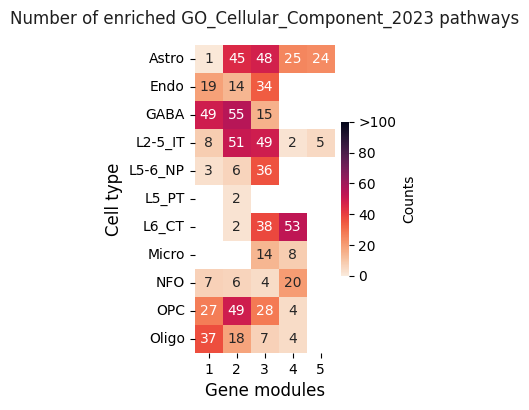

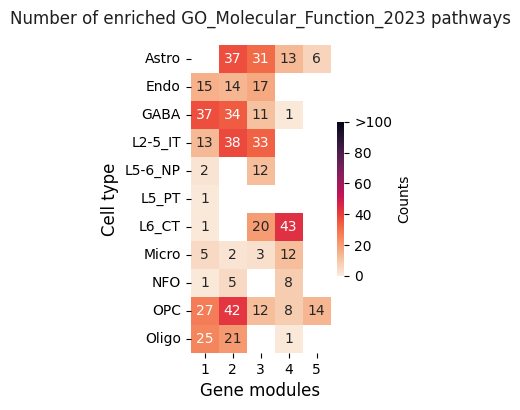

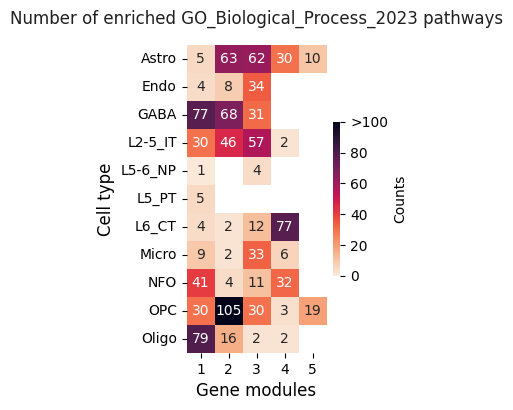

In [30]:
# Redirect output to log file
log_file = f"{date}/gsea_pipeline.log"

# Remove all existing handlers
for handler in logging.root.handlers[:]:
    logging.root.removeHandler(handler)

logging.basicConfig(
    filename=log_file,
    filemode='w',          # Overwrite existing log
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s'
)

# Redirect all stdout and stderr to the log file
sys.stdout = open(log_file, 'a')
sys.stderr = open(log_file, 'a')

folders_atlases = {
    'GO_cellular': 'GO_Cellular_Component_2023',
    'GO_molecular': 'GO_Molecular_Function_2023',
    'GO_biological': 'GO_Biological_Process_2023'
}

for folder, atlas in folders_atlases.items():
    logging.info(f"Starting GSEA pipeline for folder: {folder}, atlas: {atlas}")
    gsea_pipeline(date, folder, atlas, pval=0.05)
    logging.info(f"Finished GSEA pipeline for folder: {folder}")


In [31]:
def compile_gsea_hits(date, folder, cell_types, comps=3, pval=0.05, outfile_prefix="GSEA"):
    """
    Compile significant GSEA hits from previously saved CSV files for multiple cell types
    and components, and save as a single summary CSV.

    Parameters
    ----------
    date : str
        Base folder containing the GSEA results (e.g., 'October_2025').
    folder : str
        Subfolder for the specific GO category (e.g., 'GO_cellular').
    cell_types : list of str
        List of cell types to process.
    comps : int, optional
        Number of PLS components to process (default is 3).
    pval : float, optional
        Significance threshold to filter GSEA hits (default is 0.05).
    outfile_prefix : str, optional
        Prefix for the output CSV filename (default is "GSEA").

    Returns
    -------
    pd.DataFrame
        Concatenated DataFrame of all significant GSEA hits with cell type and component info.
    """

    new_path = f'{date}/{folder}'
    hits_list = []

    for cell_type in cell_types:
        print(f"Processing {cell_type} in {folder}...")
        # Load previously computed PLS model and condition if needed
        pls = joblib.load(f'{date}/pls_pca/pls_{cell_type}.gz')
        subset_df = gene_exp_df.loc[gene_exp_df.subtype==cell_type]
        condition = pd.get_dummies(subset_df.condition, dtype=int)['PSY'].replace(0,-1).to_numpy()
        x_loadings = np.load(f'{date}/pls_pca/flipped/x_loadings_{cell_type}.npy')

        for comp in tqdm(range(comps)):
            # Align loadings with the sign of correlation between Y scores and condition
            rho = pearsonr(pls.y_scores_[:, comp], condition)[0]
            loadings = x_loadings[comp, :] * float(np.sign(rho))

            # Load previously saved GSEA hits
            nz_gsea_df_sig = pd.read_csv(f'{new_path}/{cell_type}_comp_{comp+1}_pval_{pval}_hits.csv', index_col=0)
            nz_gsea_df_sig = nz_gsea_df_sig.loc[nz_gsea_df_sig["FDR q-val"] < pval]

            # Add cell type and component info and append to the list
            if not nz_gsea_df_sig.empty:
                nz_gsea_df_sig["cell_type"] = cell_type
                nz_gsea_df_sig["comp"] = comp + 1
                hits_list.append(nz_gsea_df_sig)

    # Concatenate all hits and save
    if hits_list:
        outfile = f"{date}/supplementary_tables/{outfile_prefix}_{folder}.csv"
        pd.concat(hits_list, axis=0)\
          .reset_index(drop=True)\
          .set_index(["cell_type", "comp"])\
          .to_csv(outfile)
        print(f"Saved {outfile}")


In [32]:
folders = {
    'GO_cellular': 'GO_Cellular_Component_2023',
    'GO_molecular': 'GO_Molecular_Function_2023',
    'GO_biological': 'GO_Biological_Process_2023'
}

for folder_name, atlas in folders.items():
    compile_gsea_hits(date='October_2025', folder=folder_name, cell_types=cell_types, comps=3, pval=0.05, outfile_prefix=f"GSEA_{atlas.split('_')[1]}")


#### Network plots

In [33]:
def plot_network(nz_gsea_df_sig, color):
    """
    Visualize a network of enriched pathways using NetworkX.
    
    This function builds a network graph based on an enrichment dataframe, where nodes
    represent pathways (with node size proportional to the pathway's hits ratio) and edges
    represent overlap between pathways (e.g., Jaccard coefficient). Node labels are positioned
    intelligently to avoid overlapping with neighbors.

    Parameters
    ----------
    nz_gsea_df_sig : pd.DataFrame
        DataFrame of significant GSEA hits containing columns like 'Term', 'NES', and 'Hits_ratio'.
    color : str
        Color to use for nodes in the network.

    Returns
    -------
    nx : networkx.Graph
        The constructed NetworkX graph object representing the pathway network.
    """
    
    # Generate nodes and edges for the enrichment map, selecting top 20 terms
    nodes, edges = enrichment_map(nz_gsea_df_sig, top_term=20)

    # Build the graph from the edges DataFrame
    G = nx.from_pandas_edgelist(edges,
                                source='src_idx',
                                target='targ_idx',
                                edge_attr=['jaccard_coef', 'overlap_coef', 'overlap_genes'])
    # Ensure all nodes are included (even if isolated)
    G.add_nodes_from(nodes.index)

    # Initialize plot
    fig, ax = plt.subplots(figsize=(6,2), dpi=200)
    fig.tight_layout()
    fig.subplots_adjust(right=1.25)

    # Compute node coordinates using a spiral layout
    pos = nx.layout.spiral_layout(G)

    # Ensure NES (normalized enrichment score) is numeric
    nodes['NES'] = pd.to_numeric(nodes['NES'], errors='coerce')
    nodes = nodes.dropna(subset=['NES'])

    # Normalize NES values for plotting (can be used for color scaling)
    norm = plt.Normalize(vmin=nodes.NES.min() - 0.5, vmax=nodes.NES.max())
    cmap = plt.cm.Blues
    node_colors = cmap(norm(nodes.NES.values))

    # Draw nodes
    nx.draw_networkx_nodes(
        G,
        pos=pos,
        edgecolors='#CDDBD4',
        node_color=color,
        node_size=list(nodes.Hits_ratio * 1000)  # Node size proportional to hits ratio
    )

    # Draw node labels with adjusted positions to avoid overlapping nodes
    label_ratio = 1.0 / 25.0
    pos_labels = {}
    for aNode in G.nodes():
        x, y = pos[aNode]
        N = G[aNode]  # Neighbors of the node
        # Compute centroid of neighbors
        cx = sum(map(lambda n: pos[n][0], N)) / len(pos)
        cy = sum(map(lambda n: pos[n][1], N)) / len(pos)
        slopeY = (y - cy) * -1
        slopeX = (x - cx) * -1
        pos_labels[aNode] = (x + slopeX * label_ratio + 0.03, y + slopeY * label_ratio - 0.2)

    # Draw labels only for connected nodes
    connected_nodes = [n for n in G.nodes if G.degree[n] > 0]
    nx.draw_networkx_labels(
        G,
        pos=pos_labels,
        font_size=10,
        labels=nodes.Term.to_dict(),
        horizontalalignment='left',
        verticalalignment='top'
    )

    # Draw edges weighted by Jaccard coefficient
    edge_weight = nx.get_edge_attributes(G, 'jaccard_coef').values()
    nx.draw_networkx_edges(
        G,
        pos=pos,
        width=list(map(lambda x: x * 10, edge_weight)),
        edge_color='#CDDBD4'
    )

    # Return the NetworkX graph object for further manipulation if needed
    return nx


In [34]:
# # 'GO_Molecular_Function_2023'
# folder = 'GO_molecular'
# pval = 0.05

# hits_cell_df = pd.DataFrame()
# for cell_type in ['L5-6_NP']:
#     print(cell_type)
#     pls = joblib.load(f'{date}/pls_pca/pls_{cell_type}.gz')
#     subset_df = gene_exp_df.loc[gene_exp_df.subtype==cell_type]
#     condition = pd.get_dummies(subset_df.condition, dtype=int)['PSY'].replace(0,-1).to_numpy()
#     x_loadings = np.load(f'{date}/pls_pca/flipped/x_loadings_{cell_type}.npy')
#     genes = [gene.upper() for gene in overlap_genes]
#     pval = 0.05

#     cell_type_paths_df = pd.DataFrame()
#     for comp in tqdm(range(2,3)):
#         loadings = x_loadings[comp,:]
#         nz_gsea_df_sig = pd.read_csv(f'{date}/{folder}/{cell_type}_comp_{comp+1}_pval_{pval}_hits.csv')
#         #gsea2(f'{date}/{folder}', loadings, genes, comp, pval, 'GO_Biological_Process_2023', save=False)
#         # print(nz_gsea_df_sig)
#         new_term = []
#         for Term in nz_gsea_df_sig.Term:
#             new_term.append(Term.split('(')[0])
#         nz_gsea_df_sig['Term'] = new_term  
#         nx = plot_network(nz_gsea_df_sig, color='palevioletred')
#         plt.tight_layout()
#         plt.margins(0.8)  # Add % margin around plot
#         plt.savefig(f'../../Figures/psilocybin_mouse_pls/{folder}_gsea_{cell_type}_comp_{comp+1}_network_graph.svg', dpi=200, bbox_inches='tight')
#         plt.show()
#         plt.close('all')



In [35]:
# # 'GO_Molecular_Function_2023'
# folder = 'GO_cellular'
# pval = 0.05

# hits_cell_df = pd.DataFrame()
# for cell_type in ['L5-6_NP']:
#     print(cell_type)
#     pls = joblib.load(f'{date}/pls_pca/pls_{cell_type}.gz')
#     subset_df = gene_exp_df.loc[gene_exp_df.subtype==cell_type]
#     condition = pd.get_dummies(subset_df.condition, dtype=int)['PSY'].replace(0,-1).to_numpy()
#     x_loadings = np.load(f'{date}/pls_pca/flipped/x_loadings_{cell_type}.npy')
#     genes = [gene.upper() for gene in overlap_genes]
#     pval = 0.05

#     cell_type_paths_df = pd.DataFrame()
#     for comp in tqdm(range(1,2)):
#         loadings = x_loadings[comp,:]
#         nz_gsea_df_sig = pd.read_csv(f'{date}/{folder}/{cell_type}_comp_{comp+1}_pval_{pval}_hits.csv')
#         #gsea2(f'{date}/{folder}', loadings, genes, comp, pval, 'GO_Biological_Process_2023', save=False)
#         print(nz_gsea_df_sig)
#         new_term = []
#         for Term in nz_gsea_df_sig.Term:
#             new_term.append(Term.split('(')[0])
#         nz_gsea_df_sig['Term'] = new_term  
#         nx = plot_network(nz_gsea_df_sig, color='turquoise')
#         plt.tight_layout()
#         plt.margins(0.8)  # Add % margin around plot
#         plt.savefig(f'../../Figures/psilocybin_mouse_pls/{folder}_gsea_{cell_type}_comp_{comp+1}_network_graph.svg', dpi=200, bbox_inches='tight')
#         plt.show()
#         plt.close('all')



In [36]:
# folder = 'GO_biological'
# pval = 0.05

# hits_cell_df = pd.DataFrame()
# for cell_type in ['L5_PT']:
#     print(cell_type)
#     pls = joblib.load(f'{date}/pls_pca/pls_{cell_type}.gz')
#     subset_df = gene_exp_df.loc[gene_exp_df.subtype==cell_type]
#     condition = pd.get_dummies(subset_df.condition, dtype=int)['PSY'].replace(0,-1).to_numpy()
#     x_loadings = np.load(f'{date}/pls_pca/flipped/x_loadings_{cell_type}.npy')
#     genes = [gene.upper() for gene in overlap_genes]
#     pval = 0.05

#     cell_type_paths_df = pd.DataFrame()
#     for comp in tqdm(range(0,1)):
#         loadings = x_loadings[comp,:]
#         nz_gsea_df_sig = pd.read_csv(f'{date}/{folder}/{cell_type}_comp_{comp+1}_pval_{pval}_hits.csv')
#         #gsea2(f'{date}/{folder}', loadings, genes, comp, pval, 'GO_Biological_Process_2023', save=False)
#         # print(nz_gsea_df_sig)
#         new_term = []
#         for Term in nz_gsea_df_sig.Term:
#             new_term.append(Term.split('(')[0])
#         nz_gsea_df_sig['Term'] = new_term  
#         nx = plot_network(nz_gsea_df_sig, color='slateblue')
#         plt.tight_layout()
#         plt.margins(0.8)  # Add % margin around plot
#         plt.savefig(f'../../Figures/psilocybin_mouse_pls/{folder}_gsea_{cell_type}_comp_{comp+1}_network_graph.svg', dpi=200, bbox_inches='tight')
#         plt.show()
#         plt.close('all')



In [37]:
# folder = 'GO_cellular'
# pval = 0.05

# hits_cell_df = pd.DataFrame()
# for cell_type in ['L5_PT']:
#     print(cell_type)
#     pls = joblib.load(f'{date}/pls_pca/pls_{cell_type}.gz')
#     subset_df = gene_exp_df.loc[gene_exp_df.subtype==cell_type]
#     condition = pd.get_dummies(subset_df.condition, dtype=int)['PSY'].replace(0,-1).to_numpy()
#     x_loadings = np.load(f'{date}/pls_pca/flipped/x_loadings_{cell_type}.npy')
#     genes = [gene.upper() for gene in overlap_genes]
#     pval = 0.05

#     cell_type_paths_df = pd.DataFrame()
#     for comp in tqdm(range(1,2)):
#         loadings = x_loadings[comp,:]
#         nz_gsea_df_sig = pd.read_csv(f'{date}/{folder}/{cell_type}_comp_{comp+1}_pval_{pval}_hits.csv')
#         nz_gsea_df_sig_010  = gsea2(f'{date}/{folder}', loadings, genes, comp, 0.1, 'GO_Cellular_Component_2023', save=False)
#         # print(nz_gsea_df_sig)
#         new_term = []
#         for Term in nz_gsea_df_sig.Term:
#             new_term.append(Term.split('(')[0])
#         nz_gsea_df_sig['Term'] = new_term  
#         nx = plot_network(nz_gsea_df_sig, color='turquoise')
#         plt.tight_layout()
#         plt.margins(0.8)  # Add % margin around plot
#         plt.savefig(f'../../Figures/psilocybin_mouse_pls/{folder}_gsea_{cell_type}_comp_{comp+1}_network_graph.svg', dpi=200, bbox_inches='tight')
#         plt.show()
#         plt.close('all')

## Correlation with receptor expression

In [38]:
import statsmodels.api as sm
import warnings
# Suppress ConstantInputWarning from scipy.stats
# Occurs when receptor expression is constant (e.g., 0) within a given cell type
warnings.filterwarnings("ignore", category=scipy.stats.ConstantInputWarning) # if not silenced, will throw error when receptor expression is 0 in a given celll type

In [39]:
comp_cols = ['Component ' + str(col) for col in range(1, 4)]

In [40]:
# Define a custom diverging palette: pink → grey → green
custom_colors = [
    "#800080",  # Purple
    "#ECECEC",  # light beige (neutral center)
    "#F97306",  # Orange
]

# Create the colormap
custom_map = mcolors.LinearSegmentedColormap.from_list("custom_map", custom_colors, N=256)

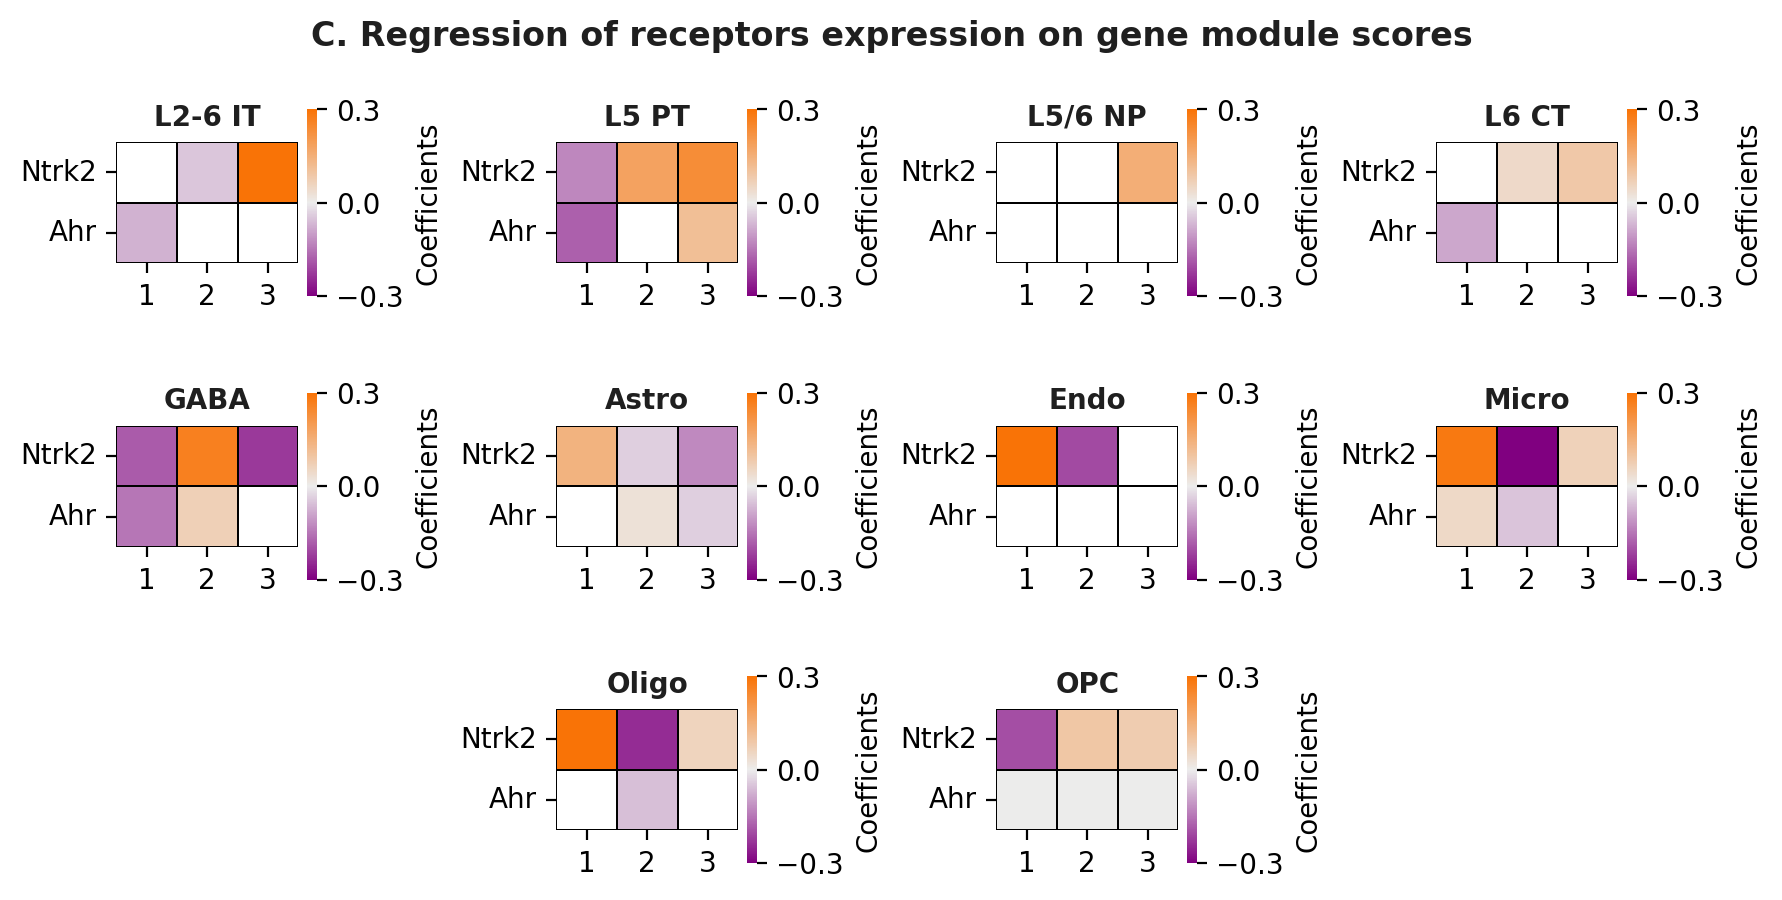

In [41]:
# Define receptors to analyze and set up grid for heatmaps
genes_to_plot = ['NTRK2', 'AHR']
n_cols, n_rows = 4, 3
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.2 * n_cols, 1.5 * n_rows), constrained_layout=True, dpi=200)
axes = axes.flatten()

# Loop through cell types and compute receptor–module regressions
for i, cell_type in enumerate(cell_types_ordered):

    if i == 8 or i == 9:  # skip empty subplot positions to keep grid layout balanced in last row
        i += 1

    subset_df = gene_exp_df.loc[gene_exp_df.subtype == cell_type]
    condition = pd.get_dummies(subset_df.condition, dtype=int)['PSY'].replace(0, -1).to_numpy()
    genes_df = subset_df[overlap_genes]
    genes_df.columns = [gene.upper() for gene in genes_df.columns]

    # Load precomputed PLS and PCA models
    pls = joblib.load(f'{date}/pls_pca/pls_{cell_type}.gz')
    pca = joblib.load(f'{date}/pls_pca/pca_{cell_type}.gz')

    # Compute PLS component correlations and z-score gene expression
    actual_Rs = np.array([pearsonr(X, Y)[0] for X, Y in zip(pls.x_scores_.T, pls.y_scores_.T)])
    genes_zscored = pd.DataFrame(StandardScaler().fit_transform(genes_df), columns=genes_df.columns)
    x_scores = pd.DataFrame(StandardScaler().fit_transform(pls.x_scores_[:, 0:3]), columns=comp_cols)

    coefs_df, pvals_df = pd.DataFrame(), pd.DataFrame()

    # Regress receptor expression on signed component scores
    for arg, comp in enumerate(comp_cols):
        rho = pearsonr(pls.x_scores_[:, arg], condition)[0]
        comp_scores = x_scores[comp].values * float(np.sign(rho))
        X = sm.add_constant(comp_scores.reshape(-1, 1))

        comp_coefs, comp_pvals = [], []
        for gene in genes_to_plot:
            y = genes_zscored[gene].values
            ols_model = sm.OLS(y, X).fit()
            comp_coefs.append(ols_model.params[1])
            comp_pvals.append(ols_model.pvalues[1])

        coefs_df[comp] = comp_coefs
        pvals_df[comp] = comp_pvals

    # Format title and plot heatmap of regression coefficients
    display_name = 'L2-6 IT' if cell_type == 'L2-5_IT' else cell_type.replace('-', '/').replace('_', ' ')
    heatmap = sns.heatmap(
        coefs_df.mask(pvals_df > 0.05),
        cmap=custom_map,
        yticklabels=[gene.capitalize() for gene in genes_to_plot],
        vmax=0.3,
        vmin=-0.3,
        xticklabels=range(1, 4),
        square=True,
        ax=axes[i],
        cbar_kws={"shrink": 0.7, "label": "Coefficients"},
        linewidth=.1,
        linecolor='black'
    )
    axes[i].set_title(display_name, fontweight='bold', fontsize=10)
    axes[i].set_yticklabels(axes[i].get_yticklabels(), rotation=0, fontsize=10)
    heatmap.collections[0].colorbar.set_ticks([-0.3, 0, 0.3])

# Remove unused subplots and save figure
fig.delaxes(axes[8])
fig.delaxes(axes[11])
fig.suptitle('C. Regression of receptors expression on gene module scores', fontweight="bold", fontsize=12)
plt.savefig('../../Figures/psilocybin_mouse_pls/snRNAseq_regression_non_sero.svg', bbox_inches='tight', dpi=200)
plt.show()
plt.close('all')


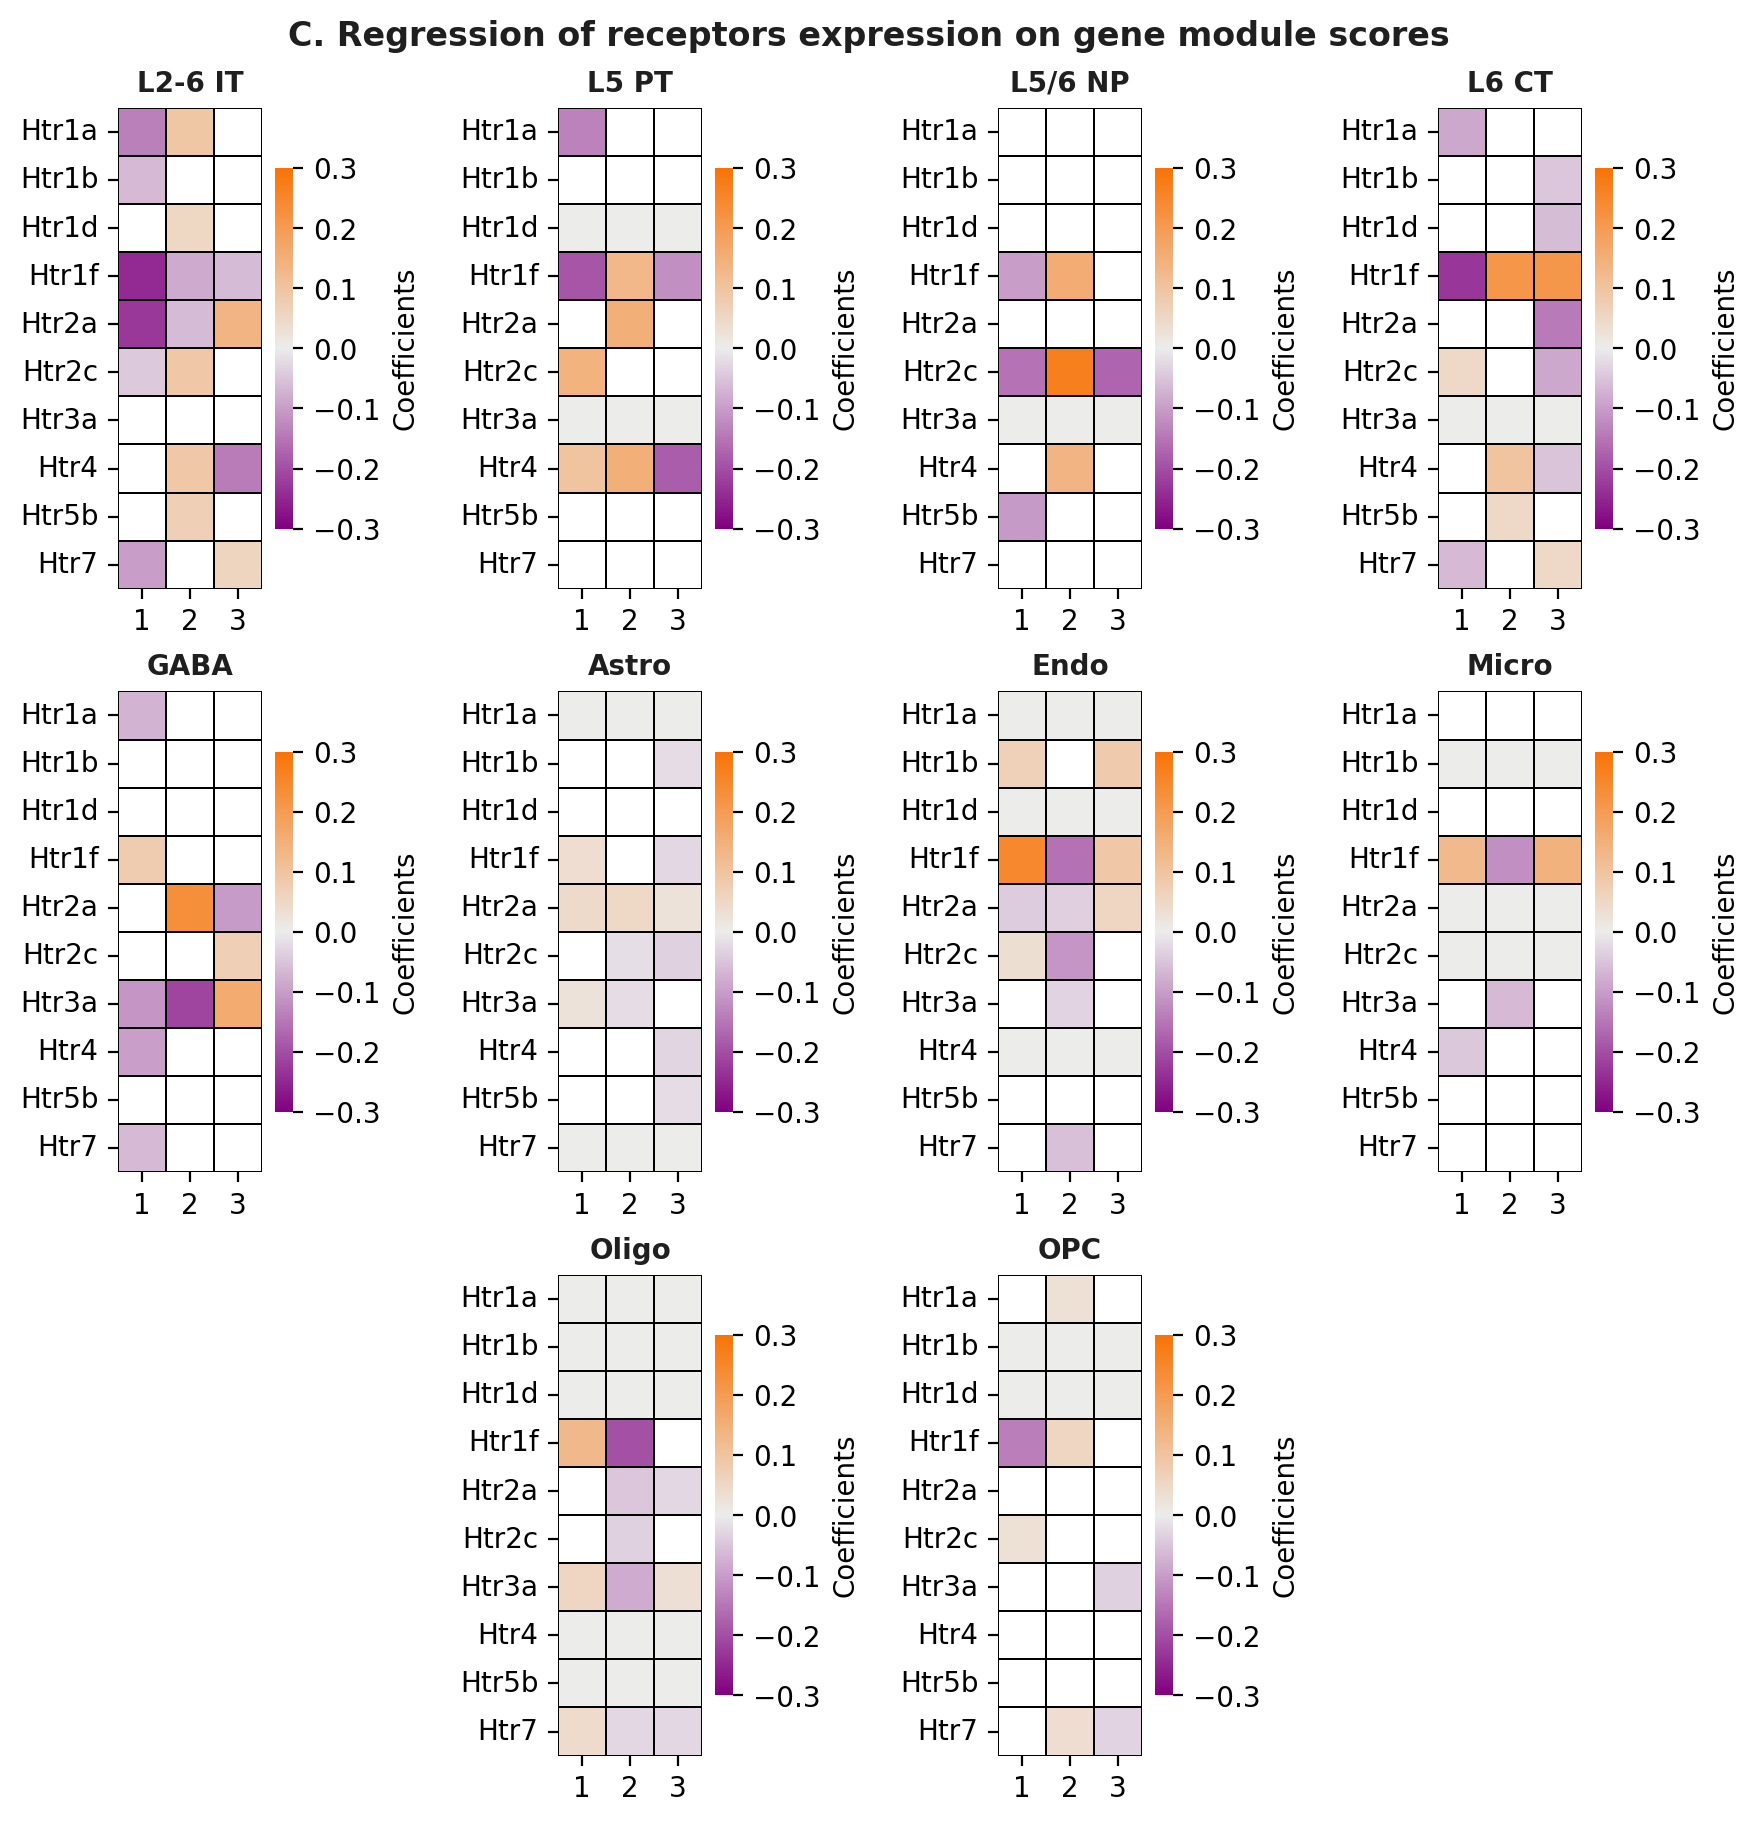

In [42]:
# Define serotonin receptors to analyze and set up grid for heatmaps
genes_to_plot = [gene.upper() for gene in sero_mouse]
n_cols, n_rows = 4, 3
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.2 * n_cols, 3 * n_rows), constrained_layout=True, dpi=200)
axes = axes.flatten()

# Loop through cell types and compute receptor–module regressions
for i, cell_type in enumerate(cell_types_ordered):

    if i == 8 or i == 9:  # skip empty subplot positions to keep grid layout balanced in last row
        i += 1

    subset_df = gene_exp_df.loc[gene_exp_df.subtype == cell_type]
    condition = pd.get_dummies(subset_df.condition, dtype=int)['PSY'].replace(0, -1).to_numpy()
    genes_df = subset_df[overlap_genes]
    genes_df.columns = [gene.upper() for gene in genes_df.columns]

    # Load precomputed PLS and PCA models
    pls = joblib.load(f'{date}/pls_pca/pls_{cell_type}.gz')
    pca = joblib.load(f'{date}/pls_pca/pca_{cell_type}.gz')

    # Compute PLS component correlations and z-score gene expression
    actual_Rs = np.array([pearsonr(X, Y)[0] for X, Y in zip(pls.x_scores_.T, pls.y_scores_.T)])
    genes_zscored = pd.DataFrame(StandardScaler().fit_transform(genes_df), columns=genes_df.columns)
    x_scores = pd.DataFrame(StandardScaler().fit_transform(pls.x_scores_[:, 0:3]), columns=comp_cols)

    coefs_df, pvals_df = pd.DataFrame(), pd.DataFrame()

    # Regress receptor expression on signed component scores
    for arg, comp in enumerate(comp_cols):
        rho = pearsonr(pls.x_scores_[:, arg], condition)[0]
        comp_scores = x_scores[comp].values * float(np.sign(rho))
        X = sm.add_constant(comp_scores.reshape(-1, 1))

        comp_coefs, comp_pvals = [], []
        for gene in genes_to_plot:
            y = genes_zscored[gene].values
            ols_model = sm.OLS(y, X).fit()
            comp_coefs.append(ols_model.params[1])
            comp_pvals.append(ols_model.pvalues[1])

        coefs_df[comp] = comp_coefs
        pvals_df[comp] = comp_pvals

    # Format title and plot heatmap of regression coefficients
    display_name = 'L2-6 IT' if cell_type == 'L2-5_IT' else cell_type.replace('-', '/').replace('_', ' ')
    heatmap = sns.heatmap(
        coefs_df.mask(pvals_df > 0.05),
        cmap=custom_map,
        yticklabels=[gene.capitalize() for gene in genes_to_plot],
        vmax=0.3,
        vmin=-0.3,
        xticklabels=range(1, 4),
        square=True,
        ax=axes[i],
        cbar_kws={"shrink": 0.75, "label": "Coefficients"},
        linewidth=.1,
        linecolor='black'
    )
    axes[i].set_title(display_name, fontweight='bold', fontsize=10)
    axes[i].set_yticklabels(axes[i].get_yticklabels(), rotation=0, fontsize=10)

# Remove unused subplots and save figure
fig.delaxes(axes[8])
fig.delaxes(axes[11])
fig.suptitle('C. Regression of receptors expression on gene module scores', fontweight="bold", fontsize=12)
plt.savefig('../../Figures/psilocybin_mouse_pls/snRNAseq_regression_only_sero.svg', bbox_inches='tight', dpi=200)
plt.show()
plt.close('all')


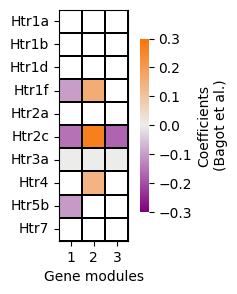

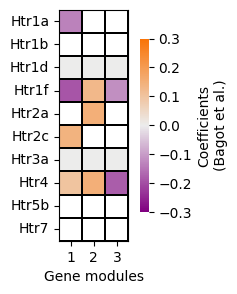

In [43]:
# Set up parameters for regression and plotting
n_cols, n_rows = 6, 2

# Loop through selected projection neuron types
for i, cell_type in enumerate(['L5-6_NP', 'L5_PT']):

    print(cell_type)
    subset_df = gene_exp_df.loc[gene_exp_df.subtype == cell_type]
    condition = pd.get_dummies(subset_df.condition, dtype=int)['PSY'].replace(0, -1).to_numpy()
    genes_df = subset_df[overlap_genes]
    genes_df.columns = [gene.upper() for gene in genes_df.columns]

    # Load precomputed PLS and PCA models
    pls = joblib.load(f'{date}/pls_pca/pls_{cell_type}.gz')
    pca = joblib.load(f'{date}/pls_pca/pca_{cell_type}.gz')

    # Compute PLS component correlations and z-score gene expression
    actual_Rs = np.array([pearsonr(X, Y)[0] for X, Y in zip(pls.x_scores_.T, pls.y_scores_.T)])
    genes_zscored = pd.DataFrame(StandardScaler().fit_transform(genes_df), columns=genes_df.columns)
    x_scores = pd.DataFrame(StandardScaler().fit_transform(pls.x_scores_[:, 0:3]), columns=comp_cols)

    # Subset serotonin receptor expression
    sero_genes = [gene.upper() for gene in sero_mouse]
    sero_exp = genes_zscored[sero_genes]

    coefs_df, pvals_df = pd.DataFrame(), pd.DataFrame()

    # Regress serotonin receptor expression on signed component scores
    for arg, comp in enumerate(comp_cols):
        rho = pearsonr(pls.x_scores_[:, arg], condition)[0]
        comp_scores = x_scores[comp].values * float(np.sign(rho))
        X = sm.add_constant(comp_scores.reshape(-1, 1))

        comp_coefs, comp_pvals = [], []
        for gene in sero_genes:
            y = sero_exp[gene].values
            ols_model = sm.OLS(y, X).fit()
            comp_coefs.append(ols_model.params[1])
            comp_pvals.append(ols_model.pvalues[1])

        coefs_df[comp] = comp_coefs
        pvals_df[comp] = comp_pvals

    # Plot heatmap of regression coefficients for each cell type
    plt.figure(figsize=(3, 3), dpi=100)
    heatmap = sns.heatmap(
        coefs_df.mask(pvals_df > 0.05),
        cmap=custom_map, square=True,
        vmax=0.3,
        vmin=-0.3,
        yticklabels=sero_mouse,
        xticklabels=range(1, 4),
        cbar_kws={"shrink": 0.75, "label": "Coefficients\n(Bagot et al.)"},
        linewidth=.1, linecolor='black'
    )
    heatmap.spines[:].set_visible(True)
    plt.xlabel('Gene modules')
    plt.savefig(f'../../Figures/psilocybin_mouse_pls/snRNAseq_{cell_type.replace("/", "_")}_{cell_type}.svg', dpi=200, bbox_inches='tight')
    plt.show()
    plt.close('all')
